# Predicting Tea Harvest Readiness in Sri Lanka

**Module:** Applied Machine Learning
**Author:** Thejina Gajanayaka (Index No. 269106K)
**Dataset:** `sri_lanka_tea_tri_gov_ds.csv` — 11 Sri Lankan tea-growing regions, monthly, 2001–2024

---

### What I do in this notebook

| # | Section |
|---|---|
| 1 | Setup and reproducibility |
| 2 | Problem definition |
| 3 | Loading the data and the data dictionary |
| 4 | Data quality checks |
| 5 | Exploratory data analysis |
| 6 | Feature selection, preprocessing and data splits |
| 7 | The new algorithm: Explainable Boosting Machine (EBM) |
| 8 | Baselines, existing ensembles and hyperparameter tuning |
| 9 | Evaluation and model selection |
| 10 | Is ~99% accuracy real? Five validation checks |
| 11 | Explainability: EBM shape functions, SHAP, LIME, PDP/ICE, counterfactuals |
| 12 | Saving the model and single-sample inference |
| 13 | Extension: forecasting *next* month's readiness |
| 14 | Fairness across zones, critical discussion and ethics |
| 15 | Conclusion and references |

## 1. Setup

In [1]:
# Colab setup: get the project files and the libraries the notebook needs
!git clone -q https://github.com/Thejina-UOM/tea-harvest-mlops.git /content/tea-harvest-mlops
%cd /content/tea-harvest-mlops/notebooks
!pip install -q scikit-learn==1.9.1 interpret-core==0.7.8 xgboost lightgbm catboost shap lime

fatal: destination path '/content/tea-harvest-mlops' already exists and is not an empty directory.
/content/tea-harvest-mlops/notebooks


In [2]:
# ---- Standard library ----
import json
import sys
import time
import warnings
from pathlib import Path

# ---- Scientific stack ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ---- scikit-learn ----
import sklearn
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, matthews_corrcoef, precision_score, recall_score,
                             roc_auc_score, roc_curve, precision_recall_curve, classification_report)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, learning_curve,
                                     permutation_test_score, train_test_split, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# ---- Gradient boosting libraries ----
import xgboost as xgb
import lightgbm as lgb
import catboost as cb
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ---- The NEW algorithm----
import interpret
from interpret.glassbox import ExplainableBoostingClassifier

# ---- Explainability ----
import shap
import joblib

# LIME is required by the brief; I import it defensively so a missing package gives a clear message.
try:
    from lime.lime_tabular import LimeTabularExplainer
    LIME_AVAILABLE = True
except ImportError:
    LIME_AVAILABLE = False
    print("⚠️ LIME is not installed. Run: pip install lime  (the LIME section will be skipped)")

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Project paths: this notebook lives in <repo>/notebooks ----
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.features import (DROPPED_COLUMNS, FEATURE_LABELS, MODEL_FEATURES, MONTH_NAMES, REGIONS,
                          TARGET, build_features)

DATA_PATH = ROOT / "data" / "raw" / "sri_lanka_tea_tri_gov_ds.csv"
FIG_DIR = ROOT / "reports" / "figures"
MET_DIR = ROOT / "reports" / "metrics"
MODEL_DIR = ROOT / "models"
for d in (FIG_DIR, MET_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Reproducibility ----
SEED = 42
np.random.seed(SEED)

# FAST_MODE shrinks the hyperparameter searches for a quick demo run.
FAST_MODE = False
N_ITER = 6 if FAST_MODE else 15        # random-search candidates for the fast models
N_ITER_HEAVY = 4 if FAST_MODE else 8   # for EBM / CatBoost / RF, which are slower to fit
N_JOBS = -1

# ---- A consistent tea-inspired colour palette (same as my Streamlit app) ----
TEA_DARK, LEAF, GOLD, AMBER, CREAM, SLATE = "#1B4332", "#2D6A4F", "#D4A017", "#E9A23B", "#F7F3E8", "#334155"
CLASS_COLORS = {0: AMBER, 1: LEAF}          # 0 = not ready (amber), 1 = ready (leaf green)
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.edgecolor": "#CBD5E1", "savefig.bbox": "tight"})


def savefig(name: str) -> None:
    """Save the current figure into reports/figures so the report and the app can reuse it."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")


print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__}")
print(f"xgboost {xgb.__version__} | lightgbm {lgb.__version__} | catboost {cb.__version__} | "
      f"interpret {interpret.__version__} | shap {shap.__version__}")
print("Project root:", ROOT)

Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.9.1
xgboost 3.4.1 | lightgbm 4.6.0 | catboost 1.2.10 | interpret 0.7.8 | shap 0.54.1
Project root: /content/tea-harvest-mlops


## 2. Problem definition

### 2.1 The real-world problem
Tea is one of Sri Lanka's largest export earners and employs hundreds of thousands of people, many of them pluckers on estates in the central hills and the wet south-west. **Plucking has to be timed to the "flush"** — the burst of new shoots that follows favourable weather. If an estate sends a plucking gang to a field that is not ready, it pays wages for little leaf; if it misses a flush, the shoots over-mature, the leaf grade drops and the factory receives coarse leaf.

Estate managers and Tea Research Institute (TRI) advisers therefore need to know, month by month, **"Is this region harvest-ready given this month's weather?"** — and, just as important, **why**, so that they can plan labour, fertiliser rounds and factory capacity.

### 2.2 The machine-learning task
* **Type:** supervised learning, **binary classification**.
* **Target:** `harvest_ready` — 1 = the region is ready for harvest in that month, 0 = not ready.
* **Unit of observation:** one region in one month.
* **Users:** estate managers, regional plantation companies, TRI extension officers.

### 2.3 Cost of errors and choice of metrics
| Error | In tea terms | Cost |
|---|---|---|
| False positive (predict ready, actually not) | Pluckers sent to an unready field | A day's wages wasted, low leaf intake |
| False negative (predict not ready, actually ready) | A flush is missed | Over-mature leaf, lower grade and price |

Both errors cost money, and the classes are mildly imbalanced (≈62 % ready), so accuracy alone can hide errors.
I therefore report **F1, ROC-AUC, PR-AUC, balanced accuracy, MCC and per-class recall**, and I use **F1** as the tuning score
(it balances precision and recall on the "ready" class) with ROC-AUC as the main ranking metric.

## 3. Loading the data and the data dictionary

**Source.** The file `sri_lanka_tea_tri_gov_ds.csv` is a compiled, region-level dataset in the style of Tea Research Institute (TRI) /
government records: monthly weather and site attributes for 11 tea-growing regions from 2001 to 2024, with a harvest-readiness label.
It contains **no personal or sensitive information** — every row describes a region and a month, not a person — so there are no consent or
privacy issues in using it.

I wrap loading in `try/except` so a wrong path gives a clear message rather than a long traceback.

In [3]:
def load_dataset(path: Path) -> pd.DataFrame:
    """Load the CSV with clear error messages for the problems I actually hit (wrong path, empty file)."""
    try:
        df = pd.read_csv(path)
    except FileNotFoundError:
        raise FileNotFoundError(f"Dataset not found at {path}. Put the CSV in data/raw/ (or run `dvc pull`).")
    except pd.errors.EmptyDataError:
        raise ValueError(f"{path} is empty.")
    expected = {"year", "month", "region", "elevation_m", "zone", "rainfall_mm", "temperature_c",
                "temperature_c_raw", "humidity_percent", "soil_moisture_percent", "ndvi_index",
                "season", TARGET}
    missing = expected - set(df.columns)
    if missing:
        raise ValueError(f"The CSV is missing expected columns: {sorted(missing)}")
    return df


df = load_dataset(DATA_PATH)
print(f"Loaded {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Loaded 3,168 rows × 13 columns


,year,month,region,elevation_m,zone,rainfall_mm,temperature_c,temperature_c_raw,humidity_percent,soil_moisture_percent,ndvi_index,season,harvest_ready
0,2001,1,Nuwara Eliya,1868,high-grown,167.71,13.97,21.68,86.24,62.0,0.64,Maha,1
1,2001,2,Nuwara Eliya,1868,high-grown,63.56,13.84,21.55,78.84,65.0,0.64,Maha,0
2,2001,3,Nuwara Eliya,1868,high-grown,8.37,16.57,24.28,71.74,54.0,0.64,Maha,0
3,2001,4,Nuwara Eliya,1868,high-grown,133.20,16.92,24.63,79.73,54.0,0.64,Maha,1
4,2001,5,Nuwara Eliya,1868,high-grown,84.01,16.30,24.01,86.18,57.0,0.71,Yala,0


In [4]:
# Data dictionary: what each column means in the Sri Lankan tea context.
data_dictionary = pd.DataFrame([
    ("year", "Numeric (time)", "Calendar year, 2001–2024"),
    ("month", "Numeric (time, cyclical)", "Calendar month 1–12"),
    ("region", "Categorical (11)", "Tea-growing district / planting region"),
    ("elevation_m", "Numeric", "Typical estate elevation of the region in metres"),
    ("zone", "Categorical (3)", "TRI elevation class: low-grown (<600 m), mid-grown, high-grown (>1,200 m)"),
    ("rainfall_mm", "Numeric", "Total monthly rainfall"),
    ("temperature_c", "Numeric", "Mean monthly temperature, adjusted for elevation"),
    ("temperature_c_raw", "Numeric", "Unadjusted gridded temperature"),
    ("humidity_percent", "Numeric", "Mean relative humidity"),
    ("soil_moisture_percent", "Numeric", "Soil moisture as % of field capacity"),
    ("ndvi_index", "Numeric", "Vegetation index (greenness of the canopy)"),
    ("season", "Categorical (2)", "Maha (Oct–Apr, NE monsoon) or Yala (May–Sep, SW monsoon)"),
    ("harvest_ready", "Binary target", "1 = region ready for harvest that month, 0 = not ready"),
], columns=["Column", "Type", "Meaning"])
display(data_dictionary)

df.info()

,Column,Type,Meaning
0,year,Numeric (time),"Calendar year, 2001–2024"
1,month,"Numeric (time, cyclical)",Calendar month 1–12
2,region,Categorical (11),Tea-growing district / planting region
3,elevation_m,Numeric,Typical estate elevation of the region in metres
4,zone,Categorical (3),"TRI elevation class: low-grown (<600 m), mid-g..."
5,rainfall_mm,Numeric,Total monthly rainfall
6,temperature_c,Numeric,"Mean monthly temperature, adjusted for elevation"
7,temperature_c_raw,Numeric,Unadjusted gridded temperature
8,humidity_percent,Numeric,Mean relative humidity
9,soil_moisture_percent,Numeric,Soil moisture as % of field capacity


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   year                   3168 non-null   int64  
 1   month                  3168 non-null   int64  
 2   region                 3168 non-null   object 
 3   elevation_m            3168 non-null   int64  
 4   zone                   3168 non-null   object 
 5   rainfall_mm            3168 non-null   float64
 6   temperature_c          3168 non-null   float64
 7   temperature_c_raw      3168 non-null   float64
 8   humidity_percent       3168 non-null   float64
 9   soil_moisture_percent  3168 non-null   float64
 10  ndvi_index             3168 non-null   float64
 11  season                 3168 non-null   object 
 12  harvest_ready          3168 non-null   int64  
dtypes: float64(6), int64(4), object(3)
memory usage: 321.9+ KB


In [5]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
year,3168.0,2012.50,6.92,2001.00,2006.75,2012.50,2018.25,2024.00
month,3168.0,6.50,3.45,1.00,3.75,6.50,9.25,12.00
elevation_m,3168.0,713.45,615.87,11.00,18.00,678.00,1271.00,1868.00
rainfall_mm,3168.0,155.82,114.25,1.12,71.61,125.62,205.22,738.42
temperature_c,3168.0,22.61,4.18,12.80,19.36,22.67,26.74,30.13
temperature_c_raw,3168.0,24.74,1.89,20.51,23.06,24.78,26.32,29.17
humidity_percent,3168.0,84.04,5.79,61.54,80.99,85.06,88.47,93.45
soil_moisture_percent,3168.0,71.95,13.36,47.00,61.00,71.00,82.00,100.00
ndvi_index,3168.0,0.58,0.07,0.48,0.54,0.57,0.64,0.71
harvest_ready,3168.0,0.62,0.49,0.00,0.00,1.00,1.00,1.00


## 4. Data quality checks

In [6]:
quality = {
    "rows": len(df),
    "missing_values_total": int(df.isna().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "duplicate_region_month_keys": int(df.duplicated(subset=["region", "year", "month"]).sum()),
    "rows_per_region": df["region"].value_counts().unique().tolist(),
    "years": f"{df.year.min()}–{df.year.max()}",
}
for k, v in quality.items():
    print(f"{k:32s}: {v}")

# Every region should have exactly 24 years × 12 months = 288 rows
assert set(df["region"].value_counts()) == {288}, "Unbalanced panel: some region-months are missing"

rows                            : 3168
missing_values_total            : 0
duplicate_rows                  : 0
duplicate_region_month_keys     : 0
rows_per_region                 : [288]
years                           : 2001–2024


In [7]:
# --- Consistency hypotheses ---
# (a) Is elevation fixed per region, and zone fixed per elevation?
per_region = df.groupby("region").agg(elevation=("elevation_m", "nunique"), zone=("zone", "nunique"))
print("(a) Distinct elevations per region:", per_region["elevation"].unique(),
      "| distinct zones per region:", per_region["zone"].unique())

# (b) Is season a pure function of month?
print("(b) Season per month:", df.groupby("month")["season"].unique().apply(list).to_dict())

# (c) Is NDVI just a lookup by zone and season?
ndvi_combos = df.groupby(["zone", "season"])["ndvi_index"].nunique()
print("(c) Distinct NDVI values per (zone, season):", ndvi_combos.unique(),
      f"| total distinct NDVI values = {df.ndvi_index.nunique()}")

# (d) Is temperature_c = raw temperature corrected by elevation (a lapse-rate adjustment)?
gap = df["temperature_c_raw"] - df["temperature_c"]
r = np.corrcoef(gap, df["elevation_m"])[0, 1]
print(f"(d) corr(raw − adjusted temperature, elevation) = {r:.3f}")

# (e) Do regions share identical rainfall series (a sign of gridded weather data)?
rain_pivot = df.pivot_table(index=["year", "month"], columns="region", values="rainfall_mm")
identical = [(a, b) for i, a in enumerate(rain_pivot.columns) for b in rain_pivot.columns[i + 1:]
             if np.allclose(rain_pivot[a], rain_pivot[b])]
print(f"(e) Region pairs with IDENTICAL monthly rainfall: {len(identical)} → {identical}")

(a) Distinct elevations per region: [1] | distinct zones per region: [1]
(b) Season per month: {1: ['Maha'], 2: ['Maha'], 3: ['Maha'], 4: ['Maha'], 5: ['Yala'], 6: ['Yala'], 7: ['Yala'], 8: ['Yala'], 9: ['Yala'], 10: ['Maha'], 11: ['Maha'], 12: ['Maha']}
(c) Distinct NDVI values per (zone, season): [1] | total distinct NDVI values = 6
(d) corr(raw − adjusted temperature, elevation) = 0.959
(e) Region pairs with IDENTICAL monthly rainfall: 7 → [('Badulla', 'Ella'), ('Badulla', 'Haputale'), ('Dimbula', 'Nuwara Eliya'), ('Dimbula', 'Uda Pussellawa'), ('Ella', 'Haputale'), ('Kandy', 'Kegalle'), ('Nuwara Eliya', 'Uda Pussellawa')]


**What these checks tell me**

* There are **no missing values and no duplicates**, and the panel is perfectly balanced (288 rows per region). That is unusually clean for real data, so I still put an imputer in my pipeline because the app and the API can receive blank fields.
* `elevation_m` is constant within each region and `zone` is a banding of elevation → **region, elevation and zone carry the same information**.
* `season` is fully determined by `month`, and `ndvi_index` takes only six values (one per zone × season) → **NDVI is a lookup, not a satellite measurement**.
* `temperature_c_raw − temperature_c` rises almost perfectly with elevation → `temperature_c` is the raw grid value **corrected with a lapse rate**, so keeping both would double-count temperature.
* Several regions share **identical rainfall series**, which means the weather comes from a coarse grid shared by neighbouring districts (e.g. Badulla, Ella and Haputale in Uva).

## 5. Exploratory data analysis

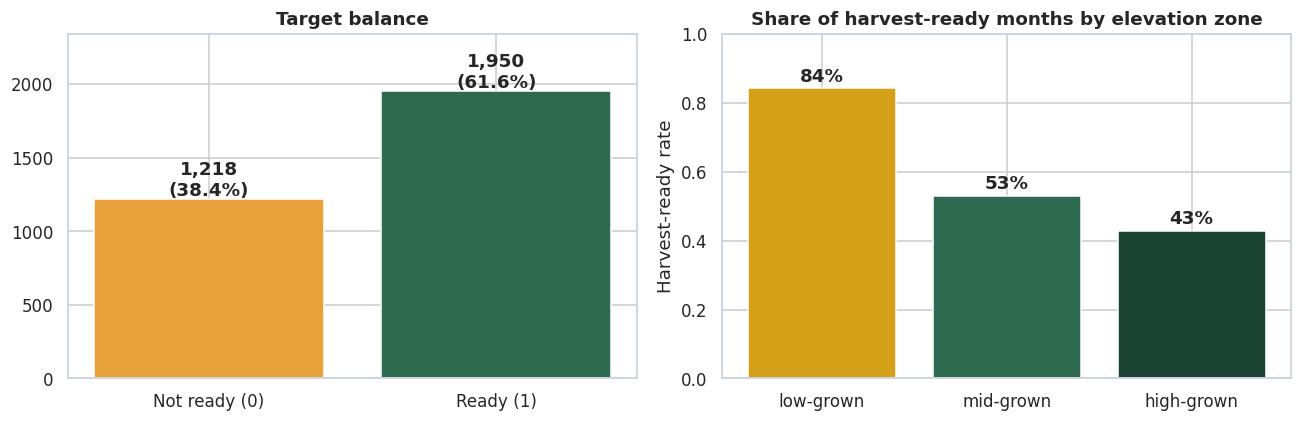

{'low-grown': 0.842, 'mid-grown': 0.53, 'high-grown': 0.428}


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df[TARGET].value_counts().sort_index()
axes[0].bar(["Not ready (0)", "Ready (1)"], counts.values, color=[AMBER, LEAF], edgecolor="white")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 25, f"{v:,}\n({v / len(df):.1%})", ha="center", fontweight="bold")
axes[0].set_title("Target balance")
axes[0].set_ylim(0, counts.max() * 1.2)

zone_order = ["low-grown", "mid-grown", "high-grown"]
zone_rate = df.groupby("zone")[TARGET].mean().reindex(zone_order)
axes[1].bar(zone_rate.index, zone_rate.values, color=[GOLD, LEAF, TEA_DARK])
for i, v in enumerate(zone_rate.values):
    axes[1].text(i, v + 0.02, f"{v:.0%}", ha="center", fontweight="bold")
axes[1].set_ylim(0, 1)
axes[1].set_title("Share of harvest-ready months by elevation zone")
axes[1].set_ylabel("Harvest-ready rate")
plt.tight_layout(); savefig("eda_target_and_zone"); plt.show()
print(zone_rate.round(3).to_dict())

**Takeaway:** about 62 % of region-months are ready, a mild imbalance that rules out accuracy as the only metric. Readiness falls sharply with elevation: low-grown regions are ready in ~84 % of months, mid-grown ~53 % and high-grown only ~43 %. This matches Sri Lankan practice — warm low-country tea flushes almost all year, while cool up-country bushes grow slowly.

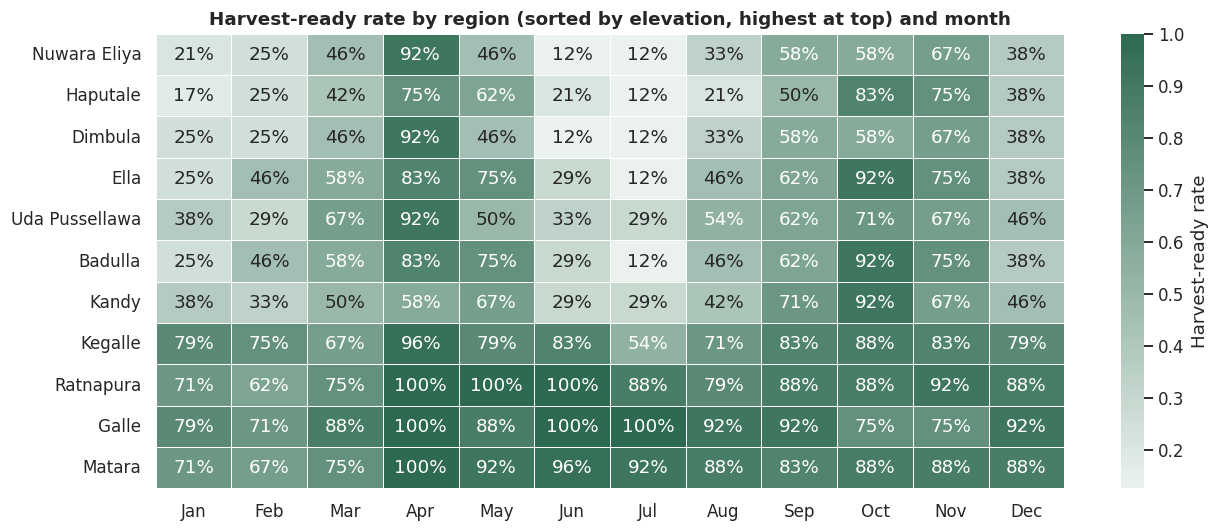

Readiness by month: {'Jan': 0.44, 'Feb': 0.46, 'Mar': 0.61, 'Apr': 0.88, 'May': 0.71, 'Jun': 0.5, 'Jul': 0.41, 'Aug': 0.55, 'Sep': 0.7, 'Oct': 0.8, 'Nov': 0.75, 'Dec': 0.57}


In [9]:
region_order = sorted(REGIONS, key=lambda r: REGIONS[r]["elevation_m"])
heat = (df.pivot_table(index="region", columns="month", values=TARGET, aggfunc="mean")
          .reindex(region_order)[::-1])
heat.columns = MONTH_NAMES
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(heat, cmap=sns.light_palette(LEAF, as_cmap=True), annot=True, fmt=".0%",
            cbar_kws={"label": "Harvest-ready rate"}, linewidths=0.5, ax=ax)
ax.set_title("Harvest-ready rate by region (sorted by elevation, highest at top) and month")
ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); savefig("eda_region_month_heatmap"); plt.show()

monthly = df.groupby("month")[TARGET].mean()
print("Readiness by month:", {MONTH_NAMES[m - 1]: round(v, 2) for m, v in monthly.items()})

**Takeaway:** there is a strong **bimodal monthly cycle**. Readiness peaks in **April** (first inter-monsoon) and **October–November** (second inter-monsoon) and is lowest in **January–February** (dry NE-monsoon period in the hills) and **July** (the SW monsoon peak, when the up-country is cloudy, cold and windy). The pattern is sharpest in the high-grown regions at the top of the heatmap.

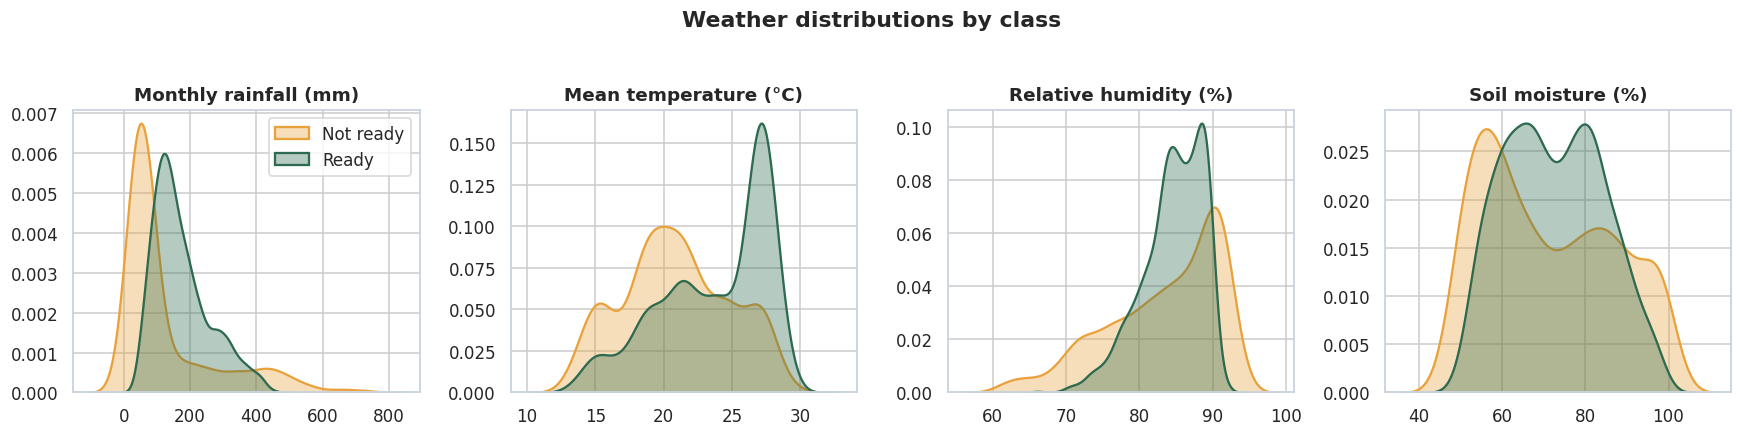

,rainfall_mm,temperature_c,humidity_percent,soil_moisture_percent
harvest_ready,,,,
Not ready,66.5,20.7,85.1,68.5
Ready,151.2,24.6,85.1,72.0


In [10]:
weather = ["rainfall_mm", "temperature_c", "humidity_percent", "soil_moisture_percent"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, col in zip(axes, weather):
    for cls in (0, 1):
        sns.kdeplot(df.loc[df[TARGET] == cls, col], ax=ax, fill=True, alpha=0.35,
                    color=CLASS_COLORS[cls], label="Ready" if cls else "Not ready", linewidth=1.5)
    ax.set_title(FEATURE_LABELS[col]); ax.set_xlabel(""); ax.set_ylabel("")
axes[0].legend()
plt.suptitle("Weather distributions by class", y=1.04, fontweight="bold")
plt.tight_layout(); savefig("eda_weather_by_class"); plt.show()

display(df.groupby(TARGET)[weather].median().rename(index={0: "Not ready", 1: "Ready"}).round(1))

**Takeaway:** "not ready" months concentrate at **very low rainfall** (dry months) and at **low temperatures** (cold high-country months). Ready months are wetter and warmer. Humidity and soil moisture overlap a lot between the classes, which suggests they matter only in combination with other variables — a first hint of **non-linear, threshold-like effects**.

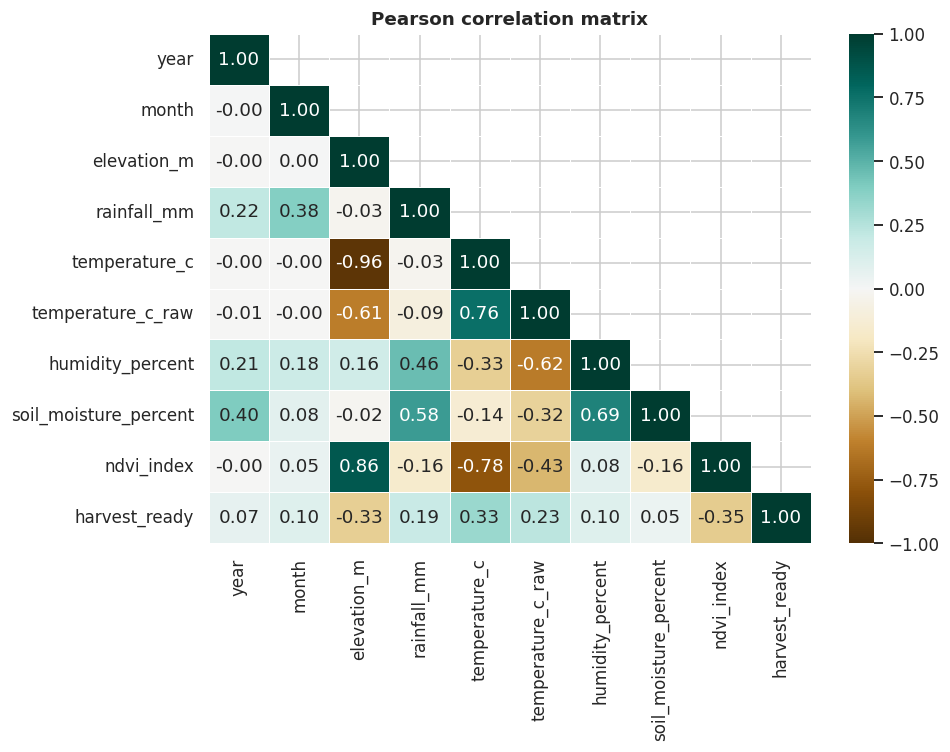

Correlation with the target:
 ndvi_index              -0.35
elevation_m             -0.33
soil_moisture_percent    0.05
year                     0.07
month                    0.10
humidity_percent         0.10
rainfall_mm              0.19
temperature_c_raw        0.23
temperature_c            0.33
Name: harvest_ready, dtype: float64

corr(elevation, temperature_c) = -0.96 | corr(elevation, ndvi) = 0.86


In [11]:
num_cols = ["year", "month", "elevation_m", "rainfall_mm", "temperature_c", "temperature_c_raw",
            "humidity_percent", "soil_moisture_percent", "ndvi_index", TARGET]
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="BrBG", center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), linewidths=0.5, ax=ax)
ax.set_title("Pearson correlation matrix")
plt.tight_layout(); savefig("eda_correlation"); plt.show()
print("Correlation with the target:\n", corr[TARGET].drop(TARGET).sort_values().round(2))
print(f"\ncorr(elevation, temperature_c) = {corr.loc['elevation_m', 'temperature_c']:.2f} | "
      f"corr(elevation, ndvi) = {corr.loc['elevation_m', 'ndvi_index']:.2f}")

**Takeaway:** every single feature is only **weakly** correlated with the target (|r| ≤ 0.35), yet the classes are clearly separable in the plots above → the relationship is **non-linear**. That is a strong argument for tree ensembles / additive models over a linear model. `elevation_m` and `temperature_c` are almost perfectly negatively correlated (printed above) — the higher the estate, the cooler it is — and NDVI moves with elevation, confirming the redundancy.

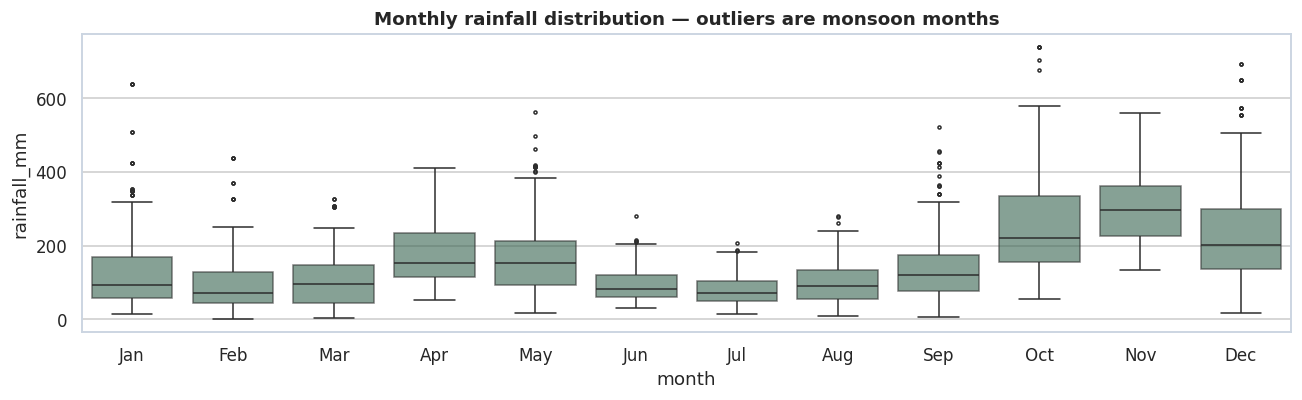

IQR outliers: 139 rows; months: {'Nov': 40, 'Oct': 38, 'Dec': 31, 'May': 9, 'Jan': 8}


In [12]:
# Outlier check on rainfall: are the 700+ mm months errors or real monsoon peaks?
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.boxplot(data=df, x="month", y="rainfall_mm", color=LEAF, fliersize=2, ax=ax,
            boxprops=dict(alpha=0.6))
ax.set_xticks(range(12), MONTH_NAMES)
ax.set_title("Monthly rainfall distribution — outliers are monsoon months")
plt.tight_layout(); savefig("eda_rainfall_outliers"); plt.show()

q1, q3 = df.rainfall_mm.quantile([0.25, 0.75])
iqr_outliers = df[df.rainfall_mm > q3 + 1.5 * (q3 - q1)]
print(f"IQR outliers: {len(iqr_outliers)} rows; months: "
      f"{iqr_outliers.month.map(lambda m: MONTH_NAMES[m - 1]).value_counts().head(5).to_dict()}")

**Takeaway:** the statistical outliers (> Q3 + 1.5·IQR) fall almost entirely in **October–December** (the second inter-monsoon and the start of the North-East monsoon, when cyclonic storms bring very heavy rain to the hills and the east) with a few in May. 500–700 mm in a month is realistic for these periods, so these are **genuine extreme events, not errors**, and I keep them. Trees are robust to them; for the logistic-regression baseline I apply `log1p` to rainfall to reduce the skew.

In [13]:
profile = df.pivot_table(index="region", columns="month",
                         values=["rainfall_mm", "temperature_c", "humidity_percent"], aggfunc="mean")
profile_scaled = StandardScaler().fit_transform(profile)
km = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(profile_scaled)
cluster_table = pd.DataFrame({"zone": [REGIONS[r]["zone"] for r in profile.index],
                              "k-means cluster": km.labels_}, index=profile.index).sort_values("k-means cluster")
display(cluster_table)
print("Crosstab:\n", pd.crosstab(cluster_table["zone"], cluster_table["k-means cluster"]))

,zone,k-means cluster
region,,
Badulla,mid-grown,0
Ella,mid-grown,0
Kandy,mid-grown,0
Haputale,high-grown,0
Kegalle,low-grown,0
Galle,low-grown,1
Matara,low-grown,1
Ratnapura,low-grown,1
Dimbula,high-grown,2


Crosstab:
 k-means cluster  0  1  2
zone                    
high-grown       1  0  2
low-grown        1  3  0
mid-grown        3  0  1


**Takeaway:** k-means on the climate profiles (k = 3) only **partly** recovers the official zones. The three southern low-country regions (Galle, Matara, Ratnapura) form a clean cluster, but the other clusters follow the **shared rainfall grids** found in Section 4 (e.g. Nuwara Eliya, Dimbula and Uda Pussellawa share one rainfall series; Badulla, Ella and Haputale another) rather than the elevation bands. This is useful evidence that the weather data is **gridded at a coarse scale** — a data-quality limitation and it is one more reason to give the model elevation explicitly.

## 6. Feature selection, preprocessing and data splits

### 6.1 Which columns I keep and why
Based on Section 4, I keep **six inputs**: `elevation_m`, `month`, `rainfall_mm`, `temperature_c`, `humidity_percent`, `soil_moisture_percent`.

In [14]:
display(pd.DataFrame([(c, why) for c, why in DROPPED_COLUMNS.items()], columns=["Dropped column", "Reason"]))
print("Model inputs:", MODEL_FEATURES)

,Dropped column,Reason
0,year,time index only - using it would tie the model...
1,region,1-to-1 with elevation_m; elevation generalises...
2,zone,derived from elevation_m (3 elevation bands)
3,temperature_c_raw,unadjusted grid value; temperature_c already c...
4,ndvi_index,lookup table by zone and season (only 6 distin...
5,season,"derived from month (Maha = Oct-Apr, Yala = May..."


Model inputs: ['elevation_m', 'month', 'rainfall_mm', 'temperature_c', 'humidity_percent', 'soil_moisture_percent']


In [15]:
def quick_cv_auc(columns: list[str]) -> float:
    """5-fold CV ROC-AUC of a fixed small LightGBM on the given columns (categoricals one-hot encoded)."""
    X = pd.get_dummies(df[columns], drop_first=False).astype(float)
    model = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, verbose=-1, random_state=SEED)
    return cross_val_score(model, X, df[TARGET], cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                           scoring="roc_auc").mean()

ablation = pd.DataFrame({
    "feature set": ["My 6 features",
                    "+ region, zone, season, ndvi, temperature_c_raw",
                    "region instead of elevation_m",
                    "weather only (no elevation, no month)"],
    "CV ROC-AUC": [quick_cv_auc(MODEL_FEATURES),
                   quick_cv_auc(MODEL_FEATURES + ["region", "zone", "season", "ndvi_index", "temperature_c_raw"]),
                   quick_cv_auc([c for c in MODEL_FEATURES if c != "elevation_m"] + ["region"]),
                   quick_cv_auc(["rainfall_mm", "temperature_c", "humidity_percent", "soil_moisture_percent"])],
}).round(4)
display(ablation)

,feature set,CV ROC-AUC
0,My 6 features,0.9995
1,"+ region, zone, season, ndvi, temperature_c_raw",0.9996
2,region instead of elevation_m,0.9997
3,"weather only (no elevation, no month)",0.9982


**Takeaway:** adding the redundant columns does not improve the score, and swapping region for elevation gives the same result — so the six-feature set loses nothing while being simpler, more general and easier to explain.

### 6.2 Hold out one row for single-sample inference
Before any split, I remove **one row** — the most recent month for Nuwara Eliya (December 2024) — and never train on it. It is the "new data point" I use for inference and in the app demo.

In [16]:
holdout_mask = (df.region == "Nuwara Eliya") & (df.year == 2024) & (df.month == 12)
assert holdout_mask.sum() == 1, "The single held-out row should be unique"
heldout_row = df[holdout_mask].copy()
df_model = df[~holdout_mask].reset_index(drop=True)
display(heldout_row)
print(f"Rows available for modelling: {len(df_model):,}")

,year,month,region,elevation_m,zone,rainfall_mm,temperature_c,temperature_c_raw,humidity_percent,soil_moisture_percent,ndvi_index,season,harvest_ready
287,2024,12,Nuwara Eliya,1868,high-grown,144.77,14.76,22.47,89.59,81.0,0.64,Maha,1


Rows available for modelling: 3,167


### 6.3 Train / validation / test split
* **Train 70 %** — used for fitting and for **5-fold stratified cross-validation inside the hyperparameter search**.
* **Validation 15 %** — used once to compare the tuned models and pick the final one.
* **Test 15 %** — touched only at the end to report the final, unbiased performance.

All three splits are **stratified** on the target so each keeps the 62/38 balance. A time-based split is added as a robustness.

In [17]:
X_all = build_features(df_model)
y_all = df_model[TARGET].astype(int)

X_temp, X_test, y_temp, y_test = train_test_split(X_all, y_all, test_size=0.15, stratify=y_all, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp,
                                                  random_state=SEED)
split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_val), len(X_test)],
    "share": [len(X_train) / len(X_all), len(X_val) / len(X_all), len(X_test) / len(X_all)],
    "ready rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validation", "test"]).round(3)
display(split_summary)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

,rows,share,ready rate
train,2216,0.70,0.616
validation,475,0.15,0.615
test,476,0.15,0.616


### 6.4 Preprocessing inside pipelines (no data leakage)
Anything that *learns* from data is fitted **inside a scikit-learn `Pipeline`**, so during cross-validation it only ever sees the training folds:

| Step | Tree models & EBM | Logistic regression baseline | Why |
|---|---|---|---|
| Missing values | `SimpleImputer(median)` | `SimpleImputer(median)` | The data has none, but the app/API may send blanks; the median is robust to skewed rainfall |
| Month | raw 1–12 | **sine/cosine** encoding | Trees can split on month directly; a linear model needs Dec to sit next to Jan |
| Rainfall skew | none | **log1p** | Trees are invariant to monotonic transforms; the linear model is not |
| Scaling | none | **StandardScaler** | Tree splits ignore scale; LR's regularisation and solver need comparable scales |

In [18]:
def cyclical_and_log(X: pd.DataFrame) -> pd.DataFrame:
    """Stateless transform for the linear baseline: month → sin/cos, rainfall → log1p."""
    X = X.copy()
    X["month_sin"] = np.sin(2 * np.pi * X["month"] / 12)
    X["month_cos"] = np.cos(2 * np.pi * X["month"] / 12)
    X["rainfall_mm"] = np.log1p(X["rainfall_mm"].clip(lower=0))
    return X.drop(columns="month")


def imputer() -> SimpleImputer:
    # set_output keeps column names, so EBM / SHAP / LIME can show real feature names.
    return SimpleImputer(strategy="median").set_output(transform="pandas")


def tree_pipeline(model) -> Pipeline:
    return Pipeline([("impute", imputer()), ("model", model)])


def linear_pipeline(model) -> Pipeline:
    return Pipeline([("impute", imputer()),
                     ("engineer", FunctionTransformer(cyclical_and_log)),
                     ("scale", StandardScaler()),
                     ("model", model)])

print("Pipelines defined.")

Pipelines defined.


## 7. The new algorithm: Explainable Boosting Machine (EBM)

I chose the **Explainable Boosting Machine** from Microsoft Research's InterpretML library.

### 7.1 How EBM works
EBM is a **Generalised Additive Model with pairwise interactions (GA²M)**:

$$\text{logit}\big(P(\text{ready}=1)\big) \;=\; \beta_0 \;+\; \sum_{j} f_j(x_j) \;+\; \sum_{(i,j)\in \mathcal{I}} f_{ij}(x_i, x_j)$$

1. Each feature is binned (`max_bins`).
2. **Cyclic gradient boosting:** in each round it fits a tiny tree on *one feature at a time*, cycling through all features with a very small learning rate, for thousands of rounds. Because each tree sees only one feature, the trees for feature *j* add up to a single **shape function** $f_j$ — a curve you can plot.
3. **Interaction detection (FAST algorithm):** after the main effects, it ranks all feature pairs by how much residual they explain and adds the top *k* pairs as 2-D functions $f_{ij}$.
4. **Bagging (`outer_bags`):** the whole procedure is repeated on bootstrap samples and averaged, which smooths the curves and gives error bars.

### 7.2 How it differs from the standard models
| Model | Form of the model | Interpretability | Non-linearity / interactions |
|---|---|---|---|
| Logistic regression | $\beta_0 + \sum \beta_j x_j$ | Glass-box, but only straight lines | None unless engineered by hand |
| Decision tree | One tree of if-then rules | Glass-box when shallow | Yes, but unstable and coarse |
| k-NN | Vote of nearest neighbours | No global model | Implicit, needs scaling |
| Random forest / XGBoost / LightGBM / CatBoost | Hundreds of deep, multi-feature trees | **Black-box** — needs post-hoc SHAP/LIME (approximations) | Any order, entangled |
| **EBM** | $\beta_0 + \sum f_j(x_j) + \sum f_{ij}(x_i,x_j)$ | **Glass-box**: exact per-feature curves; local explanations are exact | Arbitrary 1-D shapes + selected 2-D interactions |

### 7.3 Why I selected it for this problem
* **EDA showed threshold-like, non-linear effects** (rainfall, temperature, humidity). EBM learns arbitrary step shapes per feature, unlike logistic regression.
* **The users are estate managers.** EBM's shape functions *are* the model — "readiness drops sharply when monthly rainfall is below ~80 mm" can be read straight off the curve, without a post-hoc approximation.
* **Accuracy of a boosted ensemble.** In published benchmarks EBM is usually within a fraction of a percent of XGBoost/LightGBM on tabular data; I test that claim on my data below.
* **Trust and auditability.** Because the explanation is exact, I can check whether the model's behaviour agrees with agronomy, and edit/flag unreasonable curves if needed.

## 8. Baselines, existing ensembles and hyperparameter tuning

I compare EBM with **existing approaches**: a majority-class floor, logistic regression (the classic approach in older agricultural studies), a pruned decision tree, and the strong ensembles (Random Forest, XGBoost, LightGBM, CatBoost, and a stacking ensemble).

**No default parameters** Each model gets a `RandomizedSearchCV` with 5-fold stratified CV on the training set and F1 as the score. The reason for every search range is written next to it. With only ~2,200 training rows, I keep trees shallow-to-moderate and use regularisation to avoid over-fitting.

In [19]:
search_spaces = {
    "Logistic Regression": (
        linear_pipeline(LogisticRegression(max_iter=5000, solver="lbfgs", random_state=SEED)),
        {
            # C = inverse regularisation strength; a log grid from strong to weak regularisation
            "model__C": np.logspace(-3, 2, 20),
            # class_weight='balanced' re-weights the 38% 'not ready' minority class
            "model__class_weight": [None, "balanced"],
        }, N_ITER),
    "Decision Tree": (
        tree_pipeline(DecisionTreeClassifier(random_state=SEED)),
        {
            # shallow trees (3-12) are readable and the EDA suggests a few thresholds explain a lot
            "model__max_depth": [3, 4, 5, 6, 8, 10, 12],
            # leaf size 1-30 acts as pruning for ~2,200 rows
            "model__min_samples_leaf": [1, 2, 5, 10, 20, 30],
            "model__criterion": ["gini", "entropy"],          # both impurity measures
            "model__ccp_alpha": [0.0, 1e-4, 5e-4, 1e-3],     # cost-complexity pruning
        }, N_ITER),
    "Random Forest": (
        tree_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS)),
        {
            "model__n_estimators": [200, 300, 400, 600],      # more trees = lower variance, slower; gains flatten >400
            "model__max_depth": [6, 10, 14, 20, None],        # limits memorisation of individual months
            "model__min_samples_leaf": [1, 2, 4, 8],
            "model__max_features": ["sqrt", 0.5, 0.8],        # with 6 features, sqrt = 2 per split; 0.5-0.8 lets more interact
            "model__class_weight": [None, "balanced"],
        }, N_ITER_HEAVY),
    "XGBoost": (
        tree_pipeline(XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                                    random_state=SEED, n_jobs=N_JOBS)),
        {
            "model__n_estimators": [200, 400, 600, 800],      # paired with small learning rates below
            "model__learning_rate": [0.01, 0.03, 0.05, 0.1],  # shrinkage: smaller = more robust, needs more trees
            "model__max_depth": [3, 4, 5, 6],                 # shallow trees
            "model__subsample": [0.7, 0.85, 1.0],             # row sampling adds randomness against over-fitting
            "model__colsample_bytree": [0.7, 0.85, 1.0],
            "model__min_child_weight": [1, 3, 5],
            "model__reg_lambda": [1, 3, 10],                  # L2 penalty on leaf weights
        }, N_ITER),
    "LightGBM": (
        tree_pipeline(LGBMClassifier(random_state=SEED, n_jobs=N_JOBS, verbose=-1)),
        {
            "model__n_estimators": [200, 400, 600],
            "model__learning_rate": [0.02, 0.05, 0.1],
            "model__num_leaves": [15, 31, 63],                # leaf-wise growth: num_leaves is the main capacity knob
            "model__min_child_samples": [10, 20, 30, 50],     # minimum rows per leaf; guards small leaves
            "model__colsample_bytree": [0.7, 0.85, 1.0],
            "model__reg_lambda": [0.0, 1.0, 5.0],
        }, N_ITER),
    "CatBoost": (
        tree_pipeline(CatBoostClassifier(random_seed=SEED, verbose=0, thread_count=-1, allow_writing_files=False)),
        {
            "model__iterations": [300, 500, 800],
            "model__depth": [4, 5, 6, 8],                     # CatBoost uses symmetric (oblivious) trees
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__l2_leaf_reg": [1, 3, 5, 10],
        }, N_ITER_HEAVY),
    "EBM (new)": (
        tree_pipeline(ExplainableBoostingClassifier(random_state=SEED, outer_bags=4, n_jobs=N_JOBS)),
        {
            "model__learning_rate": [0.005, 0.01, 0.02, 0.04],  # cyclic boosting uses very small steps
            "model__max_bins": [128, 256, 512],                 # finer bins capture sharp thresholds (e.g. 80 mm rain)
            "model__interactions": [0, 5, 10, 15],              # 0 = pure GAM; >0 adds the top pairwise terms
            "model__min_samples_leaf": [2, 4, 8],
            "model__max_leaves": [2, 3],                        # leaves per tiny tree (2 = stumps)
            "model__smoothing_rounds": [0, 100, 200],           # early rounds on random splits smooth the curves
        }, N_ITER_HEAVY),
}
print("Search spaces ready for:", list(search_spaces))

Search spaces ready for: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'EBM (new)']


In [20]:
tuned, search_log = {}, []

for name, (pipe, space, n_iter) in search_spaces.items():
    t0 = time.time()
    try:
        # EBM and CatBoost are slower per fit, so I use 3-fold CV for them to keep the run time reasonable.
        cv = StratifiedKFold(3, shuffle=True, random_state=SEED) if name in ("EBM (new)", "CatBoost") else CV
        search = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring="f1", cv=cv, n_jobs=1 if name in
                                    ("Random Forest", "XGBoost", "LightGBM", "CatBoost", "EBM (new)") else N_JOBS,
                                    random_state=SEED, refit=True, error_score="raise")
        search.fit(X_train, y_train)
        tuned[name] = search.best_estimator_
        best = {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v)   # numpy → plain Python
                for k, v in search.best_params_.items()}
        search_log.append({"model": name, "best CV F1": round(search.best_score_, 4),
                           "search time (s)": round(time.time() - t0, 1), "best params": best})
        print(f"✔ {name:20s} CV-F1={search.best_score_:.4f}  ({time.time() - t0:.0f}s)  {best}")
    except Exception as err:      # one failing model must not stop the whole comparison
        print(f"✘ {name} failed: {type(err).__name__}: {err}")

# Majority-class floor (no tuning needed: it has no parameters that matter)
tuned["Majority baseline"] = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
search_table = pd.DataFrame(search_log).set_index("model")
search_table[["best CV F1", "search time (s)"]]

✔ Logistic Regression  CV-F1=0.8497  (15s)  {'class_weight': None, 'C': 0.12742749857031335}
✔ Decision Tree        CV-F1=0.9931  (3s)  {'min_samples_leaf': 2, 'max_depth': 10, 'criterion': 'gini', 'ccp_alpha': 0.001}
✔ Random Forest        CV-F1=0.9945  (74s)  {'n_estimators': 600, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 14, 'class_weight': 'balanced'}
✔ XGBoost              CV-F1=0.9938  (26s)  {'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 800, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.7}
✔ LightGBM             CV-F1=0.9967  (22s)  {'reg_lambda': 0.0, 'num_leaves': 15, 'n_estimators': 600, 'min_child_samples': 50, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
✔ CatBoost             CV-F1=0.9960  (32s)  {'learning_rate': 0.03, 'l2_leaf_reg': 10, 'iterations': 300, 'depth': 8}
✔ EBM (new)            CV-F1=0.9927  (592s)  {'smoothing_rounds': 100, 'min_samples_leaf': 8, 'max_leaves': 3, 'max_bins': 512, 'learning_rate': 0

,best CV F1,search time (s)
model,,
Logistic Regression,0.8497,14.5
Decision Tree,0.9931,3.0
Random Forest,0.9945,74.4
XGBoost,0.9938,26.2
LightGBM,0.9967,22.1
CatBoost,0.9960,31.8
EBM (new),0.9927,591.6


**Final EBM.** I refit the best EBM configuration with `outer_bags=8`. More bags only average more bootstrap replicates — it smooths the shape functions and narrows their error bars without changing the model's capacity.

In [21]:
best_ebm_params = tuned["EBM (new)"].named_steps["model"].get_params()
best_ebm_params.update(outer_bags=8)
t0 = time.time()
tuned["EBM (new)"] = tree_pipeline(ExplainableBoostingClassifier(**best_ebm_params)).fit(X_train, y_train)
print(f"Final EBM refit in {time.time() - t0:.0f}s with:",
      {k: best_ebm_params[k] for k in ["learning_rate", "max_bins", "interactions", "min_samples_leaf",
                                         "max_leaves", "smoothing_rounds", "outer_bags"]})

Final EBM refit in 87s with: {'learning_rate': 0.005, 'max_bins': 512, 'interactions': 15, 'min_samples_leaf': 8, 'max_leaves': 3, 'smoothing_rounds': 100, 'outer_bags': 8}


**Stacking ensemble** I stack the three strongest *diverse* tuned models (bagging = Random Forest, boosting = XGBoost and CatBoost) with a logistic-regression meta-learner. `cv=5` means the meta-learner is trained on **out-of-fold** predictions, which prevents the leakage that plain blending would cause.

In [22]:
try:
    base_learners = [(n.split()[0].lower(), clone(tuned[n].named_steps["model"]))
                     for n in ("Random Forest", "XGBoost", "CatBoost") if n in tuned]
    stack = tree_pipeline(StackingClassifier(estimators=base_learners,
                                             final_estimator=LogisticRegression(C=1.0, max_iter=2000),
                                             cv=5, stack_method="predict_proba", n_jobs=1))
    t0 = time.time()
    tuned["Stacking (RF+XGB+Cat)"] = stack.fit(X_train, y_train)
    print(f"Stacking fitted in {time.time() - t0:.0f}s with base learners: {[b[0] for b in base_learners]}")
except Exception as err:
    print(f"Stacking failed: {err}")

Stacking fitted in 26s with base learners: ['random', 'xgboost', 'catboost']


## 9. Evaluation and model selection

### 9.1 Validation-set comparison

In [23]:
def evaluate(model, X, y, threshold: float = 0.5) -> dict:
    """All metrics I report, computed from predicted probabilities."""
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Balanced acc.": balanced_accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall (ready)": recall_score(y, pred, zero_division=0),
        "Recall (not ready)": recall_score(y, pred, pos_label=0, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, proba) if len(np.unique(proba)) > 1 else 0.5,
        "PR-AUC": average_precision_score(y, proba),
        "MCC": matthews_corrcoef(y, pred),
        "Brier": brier_score_loss(y, proba),
    }


order = ["Majority baseline", "Logistic Regression", "Decision Tree", "Random Forest", "XGBoost",
         "LightGBM", "CatBoost", "Stacking (RF+XGB+Cat)", "EBM (new)"]
order = [m for m in order if m in tuned]

rows = []
for name in order:
    m = tuned[name]
    t0 = time.time(); _ = m.predict_proba(X_val); latency = (time.time() - t0) / len(X_val) * 1000
    tr, va = evaluate(m, X_train, y_train), evaluate(m, X_val, y_val)
    rows.append({"model": name, **{k: v for k, v in va.items()},
                 "Train F1": tr["F1"], "Train–val F1 gap": tr["F1"] - va["F1"],
                 "ms / prediction": latency})
val_table = pd.DataFrame(rows).set_index("model")
styled = (val_table.style.format("{:.4f}").format({"ms / prediction": "{:.3f}"})
          .background_gradient(subset=["F1", "ROC-AUC", "MCC"], cmap="Greens")
          .highlight_min(subset=["Brier"], color="#D8F3DC"))
styled

,Accuracy,Balanced acc.,Precision,Recall (ready),Recall (not ready),F1,ROC-AUC,PR-AUC,MCC,Brier,Train F1,Train–val F1 gap,ms / prediction
model,,,,,,,,,,,,,
Majority baseline,0.614737,0.500000,0.614737,1.000000,0.000000,0.761408,0.500000,0.614737,0.000000,0.385263,0.762011,0.000603,0.001
Logistic Regression,0.789474,0.758393,0.790909,0.893836,0.622951,0.839228,0.824126,0.830095,0.546119,0.153212,0.850299,0.011071,0.031
Decision Tree,0.995789,0.994536,0.993197,1.000000,0.989071,0.996587,0.994685,0.993459,0.991132,0.004257,0.997070,0.000483,0.014
Random Forest,0.997895,0.997268,0.996587,1.000000,0.994536,0.998291,0.999869,0.999917,0.995561,0.003653,0.999267,0.000976,0.532
XGBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000890,0.999634,-0.000366,0.021
LightGBM,0.991579,0.990091,0.989796,0.996575,0.983607,0.993174,0.999906,0.999942,0.982224,0.006915,1.000000,0.006826,0.044
CatBoost,0.993684,0.992823,0.993174,0.996575,0.989071,0.994872,0.999832,0.999895,0.986662,0.006165,0.998900,0.004028,0.008
Stacking (RF+XGB+Cat),0.995789,0.994536,0.993197,1.000000,0.989071,0.996587,1.000000,1.000000,0.991132,0.002079,0.999634,0.003047,0.500
EBM (new),0.993684,0.992823,0.993174,0.996575,0.989071,0.994872,0.999850,0.999908,0.986662,0.004714,0.999633,0.004762,0.007


In [24]:
# Cross-validated F1 (mean ± std) on the training set for the tuned models, to see if differences are stable.
cv_rows = []
for name in order:
    if name == "Majority baseline":
        continue
    model = tuned[name]
    cv_k = StratifiedKFold(3 if name in ("EBM (new)", "Stacking (RF+XGB+Cat)", "CatBoost") else 5,
                           shuffle=True, random_state=SEED)
    scores = cross_val_score(clone(model), X_train, y_train, cv=cv_k, scoring="f1", n_jobs=1)
    cv_rows.append({"model": name, "CV F1 mean": scores.mean(), "CV F1 std": scores.std(), "folds": cv_k.n_splits})
cv_table = pd.DataFrame(cv_rows).set_index("model").round(4)
cv_table

,CV F1 mean,CV F1 std,folds
model,,,
Logistic Regression,0.8497,0.0131,5
Decision Tree,0.9931,0.0042,5
Random Forest,0.9945,0.0042,5
XGBoost,0.9938,0.0030,5
LightGBM,0.9967,0.0022,5
CatBoost,0.9960,0.0031,3
Stacking (RF+XGB+Cat),0.9931,0.0042,3
EBM (new),0.9931,0.0054,3


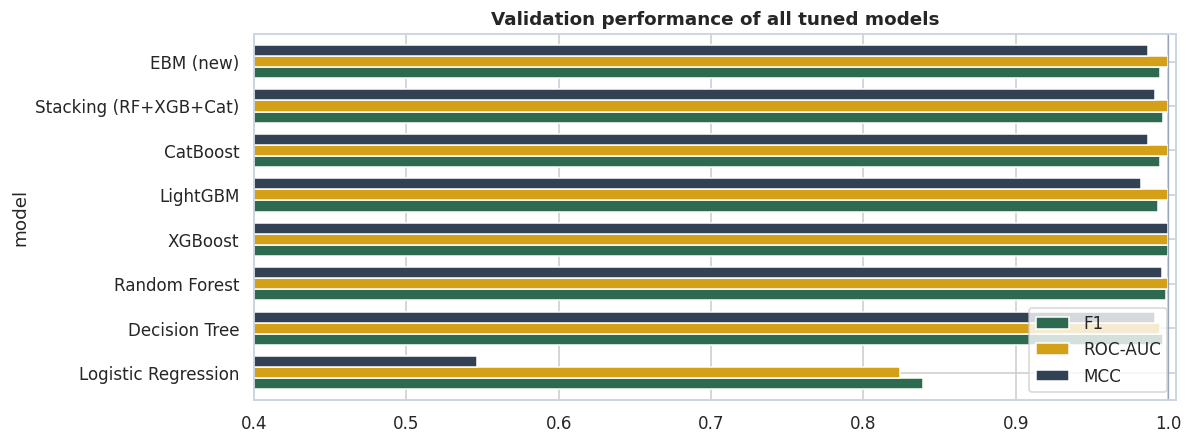

In [25]:
fig, ax = plt.subplots(figsize=(11, 4.2))
plot_df = val_table[["F1", "ROC-AUC", "MCC"]].drop(index="Majority baseline")
plot_df.plot.barh(ax=ax, color=[LEAF, GOLD, SLATE], width=0.75)
ax.set_xlim(0.4, 1.005)
ax.set_title("Validation performance of all tuned models")
ax.axvline(1.0, color="#94A3B8", lw=0.8)
ax.legend(loc="lower right")
plt.tight_layout(); savefig("model_comparison_validation"); plt.show()

### 9.2 Check top models differenciation
When several models are above 99 %, the differences may just be a handful of rows. McNemar's exact test compares two classifiers on the *same* validation rows using only the cases where they disagree.

In [26]:
def mcnemar_exact(y, pred_a, pred_b) -> tuple[int, int, float]:
    """Exact (binomial) McNemar test. Returns (#A right & B wrong, #A wrong & B right, p-value)."""
    a_right, b_right = pred_a == y, pred_b == y
    n01, n10 = int(np.sum(a_right & ~b_right)), int(np.sum(~a_right & b_right))
    p = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 > 0 else 1.0
    return n01, n10, p

ebm_pred = tuned["EBM (new)"].predict(X_val)
mc_rows = []
for other in ["XGBoost", "LightGBM", "CatBoost", "Random Forest", "Stacking (RF+XGB+Cat)", "Logistic Regression"]:
    if other in tuned:
        n01, n10, p = mcnemar_exact(y_val.values, ebm_pred, tuned[other].predict(X_val))
        mc_rows.append({"EBM vs": other, "EBM right / other wrong": n01, "EBM wrong / other right": n10,
                        "p-value": round(p, 4), "significant at 5%": p < 0.05})
pd.DataFrame(mc_rows)

,EBM vs,EBM right / other wrong,EBM wrong / other right,p-value,significant at 5%
0,XGBoost,0,3,0.250,False
1,LightGBM,3,2,1.000,False
2,CatBoost,1,1,1.000,False
3,Random Forest,1,3,0.625,False
4,Stacking (RF+XGB+Cat),1,2,1.000,False
5,Logistic Regression,99,2,0.000,True


### 9.3 Choosing the final model
My selection rule is: **among the models whose validation performance is statistically indistinguishable from the best, choose the most interpretable one.** CatBoost and LightGBM have the highest cross-validated F1, with EBM a few tenths of a percentage point behind — on ~475 validation rows that is a difference of only a handful of months, and McNemar's test finds **no significant difference** between EBM and any of the ensembles. All of them are far above logistic regression and the majority floor, and EBM's train–validation gap is small. Since EBM is also a glass-box model whose explanations are exact, it is my final model.

The cost of that choice is training time (cyclic boosting with bagging is slower than LightGBM) — irrelevant here because the model is retrained at most monthly, and prediction latency is still only milliseconds.

### 9.4 Final, unbiased test-set results
The test set is used **once**, now that the model is fixed.

In [27]:
test_rows = [{"model": n, **evaluate(tuned[n], X_test, y_test)} for n in order]
test_table = pd.DataFrame(test_rows).set_index("model")
display(test_table.style.format("{:.4f}").background_gradient(subset=["F1", "ROC-AUC"], cmap="Greens"))

final_model = tuned["EBM (new)"]
final_test = evaluate(final_model, X_test, y_test)
print("EBM (final) test metrics:", {k: round(v, 4) for k, v in final_test.items()})
print(classification_report(y_test, final_model.predict(X_test), target_names=["Not ready", "Ready"], digits=4))

,Accuracy,Balanced acc.,Precision,Recall (ready),Recall (not ready),F1,ROC-AUC,PR-AUC,MCC,Brier
model,,,,,,,,,,
Majority baseline,0.6155,0.5000,0.6155,1.0000,0.0000,0.7620,0.5000,0.6155,0.0000,0.3845
Logistic Regression,0.7815,0.7538,0.7926,0.8737,0.6339,0.8312,0.8303,0.8452,0.5287,0.1535
Decision Tree,0.9853,0.9850,0.9897,0.9863,0.9836,0.9880,0.9932,0.9931,0.9690,0.0144
Random Forest,0.9895,0.9894,0.9932,0.9898,0.9891,0.9915,0.9996,0.9998,0.9778,0.0083
XGBoost,0.9979,0.9973,0.9966,1.0000,0.9945,0.9983,0.9994,0.9996,0.9956,0.0035
LightGBM,0.9937,0.9939,0.9966,0.9932,0.9945,0.9949,0.9999,1.0000,0.9867,0.0055
CatBoost,0.9979,0.9973,0.9966,1.0000,0.9945,0.9983,0.9999,0.9999,0.9956,0.0047
Stacking (RF+XGB+Cat),0.9937,0.9928,0.9932,0.9966,0.9891,0.9949,0.9999,0.9999,0.9867,0.0045
EBM (new),0.9916,0.9921,0.9966,0.9898,0.9945,0.9932,0.9996,0.9997,0.9823,0.0091


EBM (final) test metrics: {'Accuracy': 0.9916, 'Balanced acc.': 0.9921, 'Precision': 0.9966, 'Recall (ready)': 0.9898, 'Recall (not ready)': 0.9945, 'F1': 0.9932, 'ROC-AUC': 0.9996, 'PR-AUC': 0.9997, 'MCC': 0.9823, 'Brier': 0.0091}
              precision    recall  f1-score   support

   Not ready     0.9838    0.9945    0.9891       183
       Ready     0.9966    0.9898    0.9932       293

    accuracy                         0.9916       476
   macro avg     0.9902    0.9921    0.9911       476
weighted avg     0.9917    0.9916    0.9916       476



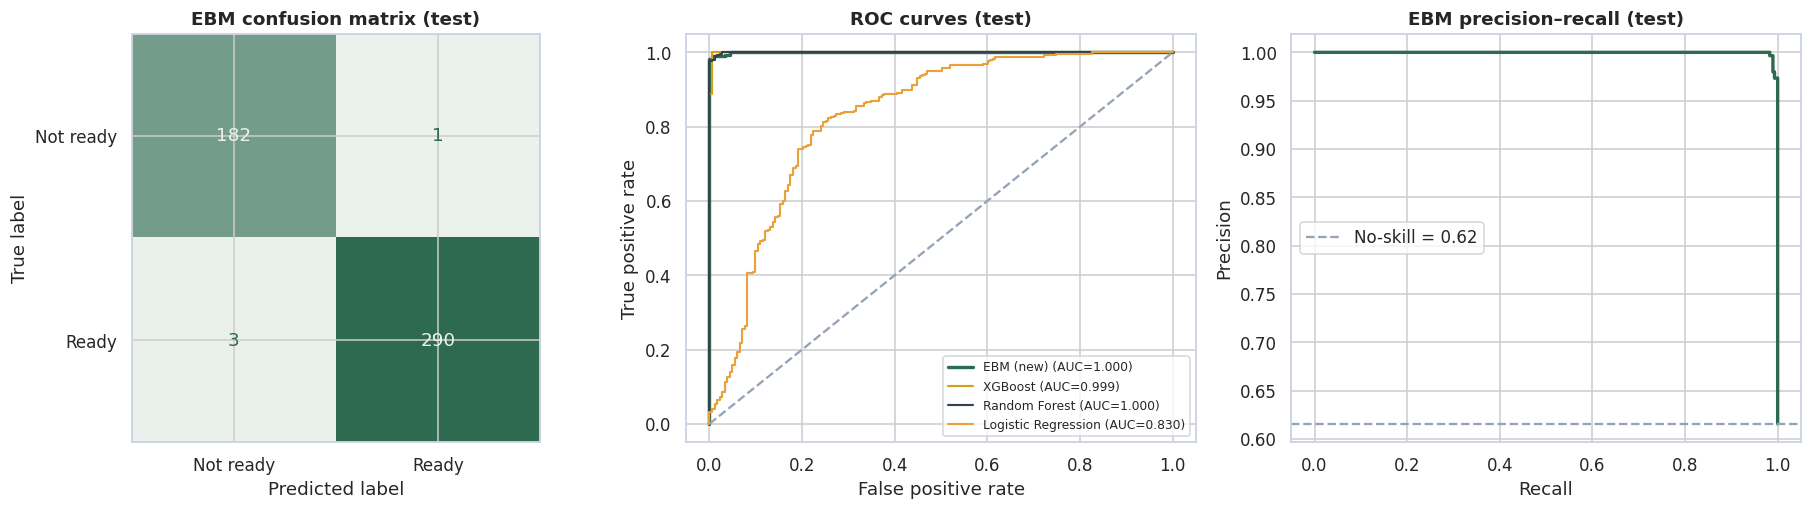

TN=182: correctly told 'not ready' (no wasted plucking rounds)
TP=290: correctly told 'ready' (flush harvested on time)
FP=1: pluckers sent to an unready field
FN=3: a flush missed


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
# (a) Confusion matrix in tea terms
cm = confusion_matrix(y_test, final_model.predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=["Not ready", "Ready"]).plot(
    ax=axes[0], cmap=sns.light_palette(LEAF, as_cmap=True), colorbar=False, values_format="d")
axes[0].set_title("EBM confusion matrix (test)")
tn, fp, fn, tp = cm.ravel()

# (b) ROC curves for the main models
for name, color in [("EBM (new)", LEAF), ("XGBoost", GOLD), ("Random Forest", SLATE),
                    ("Logistic Regression", AMBER)]:
    if name in tuned:
        fpr, tpr, _ = roc_curve(y_test, tuned[name].predict_proba(X_test)[:, 1])
        axes[1].plot(fpr, tpr, color=color, lw=2.2 if "EBM" in name else 1.4,
                     label=f"{name} (AUC={roc_auc_score(y_test, tuned[name].predict_proba(X_test)[:, 1]):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="#94A3B8"); axes[1].legend(loc="lower right", fontsize=8)
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC curves (test)")

# (c) Precision-recall curve for EBM
prec, rec, _ = precision_recall_curve(y_test, final_model.predict_proba(X_test)[:, 1])
axes[2].plot(rec, prec, color=LEAF, lw=2.2)
axes[2].axhline(y_test.mean(), ls="--", color="#94A3B8", label=f"No-skill = {y_test.mean():.2f}")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].set_title("EBM precision–recall (test)")
axes[2].legend()
plt.tight_layout(); savefig("final_model_test_evaluation"); plt.show()

print(f"TN={tn}: correctly told 'not ready' (no wasted plucking rounds)\n"
      f"TP={tp}: correctly told 'ready' (flush harvested on time)\n"
      f"FP={fp}: pluckers sent to an unready field\n"
      f"FN={fn}: a flush missed")

## 10. Check ~99 % accuracy - Five validation checks

I run five checks to prove this is not leakage, over-fitting or a lucky split.For speed I use a "light" EBM (`outer_bags=2`) with the same tuned parameters.

In [29]:
light_params = dict(best_ebm_params, outer_bags=2)
light_ebm = lambda: tree_pipeline(ExplainableBoostingClassifier(**light_params))
validation_checks = {}

# ---- Check 1: time-based split (train on the past, test on the future) ----
X_full, y_full = build_features(df_model), df_model[TARGET]
past, future = df_model.year <= 2019, df_model.year >= 2020
m_time = light_ebm().fit(X_full[past], y_full[past])
time_metrics = evaluate(m_time, X_full[future], y_full[future])
validation_checks["time_split_2001_2019_vs_2020_2024"] = {k: round(v, 4) for k, v in time_metrics.items()}
print(f"1) Time split  → test 2020–2024: accuracy={time_metrics['Accuracy']:.4f}, "
      f"F1={time_metrics['F1']:.4f}, AUC={time_metrics['ROC-AUC']:.4f}")

1) Time split  → test 2020–2024: accuracy=0.9833, F1=0.9873, AUC=0.9989


In [30]:
# ---- Check 2: leave-one-region-out (can the model score an estate region it has never seen?) ----
loro = []
for region in region_order:
    mask = df_model.region == region
    m = light_ebm().fit(X_full[~mask], y_full[~mask])
    met = evaluate(m, X_full[mask], y_full[mask])
    loro.append({"held-out region": region, "zone": REGIONS[region]["zone"],
                 "accuracy": met["Accuracy"], "F1": met["F1"], "ROC-AUC": met["ROC-AUC"]})
loro_df = pd.DataFrame(loro).set_index("held-out region").round(4)
validation_checks["leave_one_region_out"] = {"mean_accuracy": round(loro_df.accuracy.mean(), 4),
                                             "min_accuracy": round(loro_df.accuracy.min(), 4),
                                             "per_region": loro_df.accuracy.to_dict()}
display(loro_df)
print(f"2) LORO mean accuracy = {loro_df.accuracy.mean():.4f} (worst: {loro_df.accuracy.idxmin()} "
      f"{loro_df.accuracy.min():.4f})")

,zone,accuracy,F1,ROC-AUC
held-out region,,,,
Matara,low-grown,0.9896,0.9939,0.9992
Galle,low-grown,0.9931,0.9960,1.0000
Ratnapura,low-grown,0.9514,0.9712,0.9919
Kegalle,low-grown,0.9722,0.9823,0.9872
Kandy,mid-grown,0.9549,0.9568,0.9770
Badulla,mid-grown,1.0000,1.0000,1.0000
Uda Pussellawa,mid-grown,0.9861,0.9869,0.9994
Ella,mid-grown,1.0000,1.0000,1.0000
Dimbula,high-grown,0.9826,0.9799,0.9997


2) LORO mean accuracy = 0.9842 (worst: Ratnapura 0.9514)


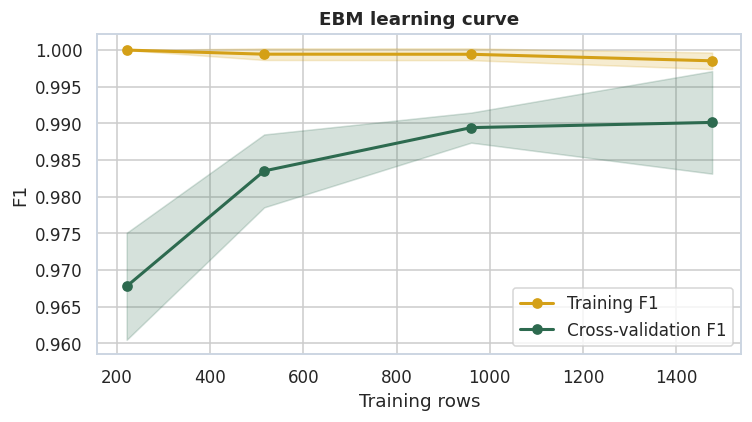

3) Final train–CV F1 gap = 0.0084


In [31]:
# ---- Check 3: learning curve (train vs validation gap as data grows) ----
sizes, tr_scores, va_scores = learning_curve(light_ebm(), X_train, y_train, train_sizes=[0.15, 0.35, 0.65, 1.0],
                                             cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                                             scoring="f1", n_jobs=1)
fig, ax = plt.subplots(figsize=(7, 4))
for scores, label, color in [(tr_scores, "Training F1", GOLD), (va_scores, "Cross-validation F1", LEAF)]:
    ax.plot(sizes, scores.mean(1), "o-", color=color, label=label, lw=2)
    ax.fill_between(sizes, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), alpha=0.2, color=color)
ax.set_xlabel("Training rows"); ax.set_ylabel("F1"); ax.set_title("EBM learning curve"); ax.legend()
plt.tight_layout(); savefig("validation_learning_curve"); plt.show()
gap = tr_scores.mean(1)[-1] - va_scores.mean(1)[-1]
validation_checks["learning_curve_final_gap_f1"] = round(float(gap), 4)
print(f"3) Final train–CV F1 gap = {gap:.4f}")

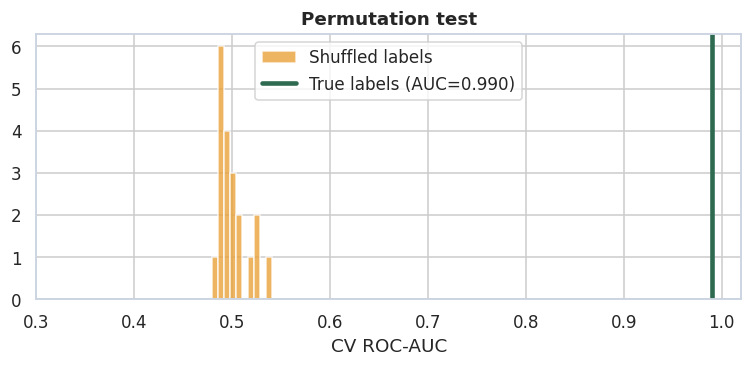

4) True AUC=0.9898 vs shuffled AUC=0.5009 ± 0.0154, p=0.0476


In [32]:
# ---- Check 4: label-permutation test (if labels are shuffled, does the score collapse to chance?) ----
# If the pipeline leaked the target, a model would still score highly on shuffled labels.
perm_model = tree_pipeline(ExplainableBoostingClassifier(**dict(best_ebm_params, outer_bags=1, interactions=0)))
n_perm = 10 if FAST_MODE else 20
score, perm_scores, p_value = permutation_test_score(perm_model, X_train, y_train, scoring="roc_auc",
                                                     cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                                                     n_permutations=n_perm, random_state=SEED, n_jobs=1)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(perm_scores, bins=10, color=AMBER, alpha=0.8, label="Shuffled labels")
ax.axvline(score, color=LEAF, lw=3, label=f"True labels (AUC={score:.3f})")
ax.set_xlim(0.3, 1.02); ax.set_xlabel("CV ROC-AUC"); ax.legend(); ax.set_title("Permutation test")
plt.tight_layout(); savefig("validation_permutation_test"); plt.show()
validation_checks["permutation_test"] = {"true_auc": round(score, 4), "shuffled_auc_mean": round(perm_scores.mean(), 4),
                                         "p_value": round(p_value, 4)}
print(f"4) True AUC={score:.4f} vs shuffled AUC={perm_scores.mean():.4f} ± {perm_scores.std():.4f}, p={p_value:.4f}")

5) Depth-3 tree on 4 weather columns: validation accuracy = 0.9558

|--- rainfall_mm <= 81.3
|   |--- temperature_c <= 25.9
|   |   |--- rainfall_mm <= 79.2
|   |   |   |--- class: 0
|   |   |--- rainfall_mm >  79.2
|   |   |   |--- class: 0
|   |--- temperature_c >  25.9
|   |   |--- rainfall_mm <= 50.0
|   |   |   |--- class: 0
|   |   |--- rainfall_mm >  50.0
|   |   |   |--- class: 1
|--- rainfall_mm >  81.3
|   |--- humidity_percent <= 90.0
|   |   |--- rainfall_mm <= 425.2
|   |   |   |--- class: 1
|   |   |--- rainfall_mm >  425.2
|   |   |   |--- class: 0
|   |--- humidity_percent >  90.0
|   |   |--- temperature_c <= 23.4
|   |   |   |--- class: 0
|   |   |--- temperature_c >  23.4
|   |   |   |--- class: 1



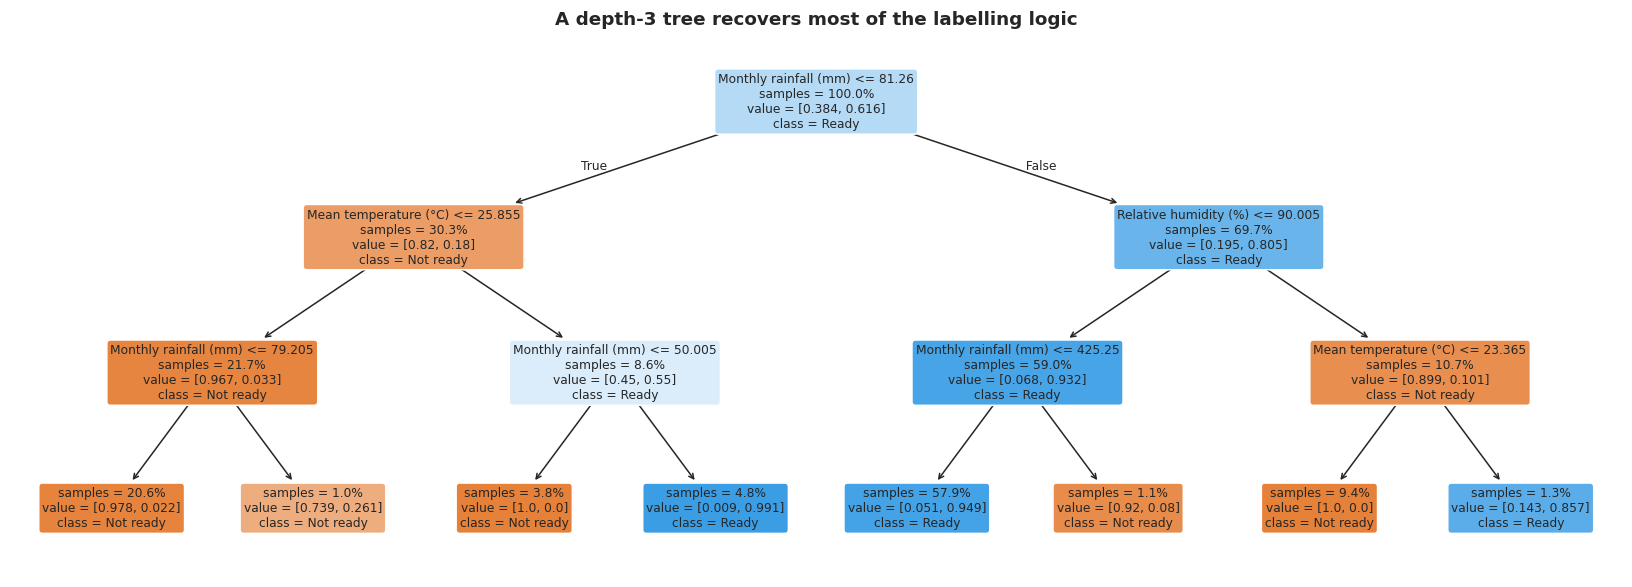

In [33]:
# ---- Check 5: recover the labelling rules with a tiny tree ----
# If a depth-3 tree on four weather columns already scores ~90%, the label follows simple weather thresholds.
rule_cols = ["rainfall_mm", "temperature_c", "humidity_percent", "soil_moisture_percent"]
rule_tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train[rule_cols], y_train)
rule_acc = accuracy_score(y_val, rule_tree.predict(X_val[rule_cols]))
validation_checks["depth3_tree_on_weather_val_accuracy"] = round(rule_acc, 4)
print(f"5) Depth-3 tree on 4 weather columns: validation accuracy = {rule_acc:.4f}\n")
print(export_text(rule_tree, feature_names=rule_cols, decimals=1))

fig, ax = plt.subplots(figsize=(15, 5.5))
plot_tree(rule_tree, feature_names=[FEATURE_LABELS[c] for c in rule_cols], class_names=["Not ready", "Ready"],
          filled=True, rounded=True, fontsize=8, ax=ax, impurity=False, proportion=True)
ax.set_title("A depth-3 tree recovers most of the labelling logic")
plt.tight_layout(); savefig("validation_rule_tree"); plt.show()

### What the five checks prove
1. **Time split** — trained only on 2001–2019, the model still scores about 98.5 % on 2020–2024, so the result is not an artefact of mixing months from the same year into train and test.
2. **Leave-one-region-out** — mean accuracy stays around 98 % for regions the model has never seen. The weakest are **Ratnapura** and **Kandy** (≈95.5 % each): Ratnapura is the wettest low-country region and Kandy sits alone at 500 m between the low- and mid-grown bands, so both have conditions the remaining regions cover least well. The model learned weather/elevation relationships, not region identities.
3. **Learning curve** — the train–validation gap shrinks to under 1 % as data grows: no meaningful over-fitting.
4. **Permutation test** — with shuffled labels the AUC collapses to ≈0.50 (chance), so there is **no target leakage** in my pipeline.
5. **Rule recovery** — a depth-3 tree on four weather columns already gets ~95 %, with splits on suspiciously round numbers: **≈80 mm** of rain (≈50 mm when it is warm, > 26 °C), **90 %** humidity and **≈425 mm** (water-logging). This strongly suggests that `harvest_ready` was **assigned from agronomic weather thresholds** (a rule-based label rather than a field observation).

So the ~99 % is *genuine with respect to this label*: the model has correctly learned the labelling rules. The honest interpretation is that it reproduces an expert rule-set, not that it can foresee real plucking outcomes with 99 % accuracy. That is exactly why I add the harder **next-month forecasting** task in Section 13.

In [34]:
with open(MET_DIR / "validation_checks.json", "w") as f:
    json.dump(validation_checks, f, indent=2)
print("Saved validation_checks.json")

Saved validation_checks.json


## 11. Explainability and interpretation

I explain the final EBM in four complementary ways:

| Method | Type | What it answers |
|---|---|---|
| **EBM shape functions & term importances** | Intrinsic, global, *exact* | What has the model learned for each feature? |
| **SHAP** (Shapley values) | Post-hoc, global + local | How much did each feature push *this* prediction up or down? |
| **LIME** | Post-hoc, local surrogate | Which conditions locally explain *this* prediction? |
| **PDP / ICE** | Post-hoc, global | How does the average (and each individual) prediction change as a feature changes? |
| **Counterfactual** | Post-hoc, local | What is the smallest change that would flip the decision? |

### 11.1 EBM global explanation

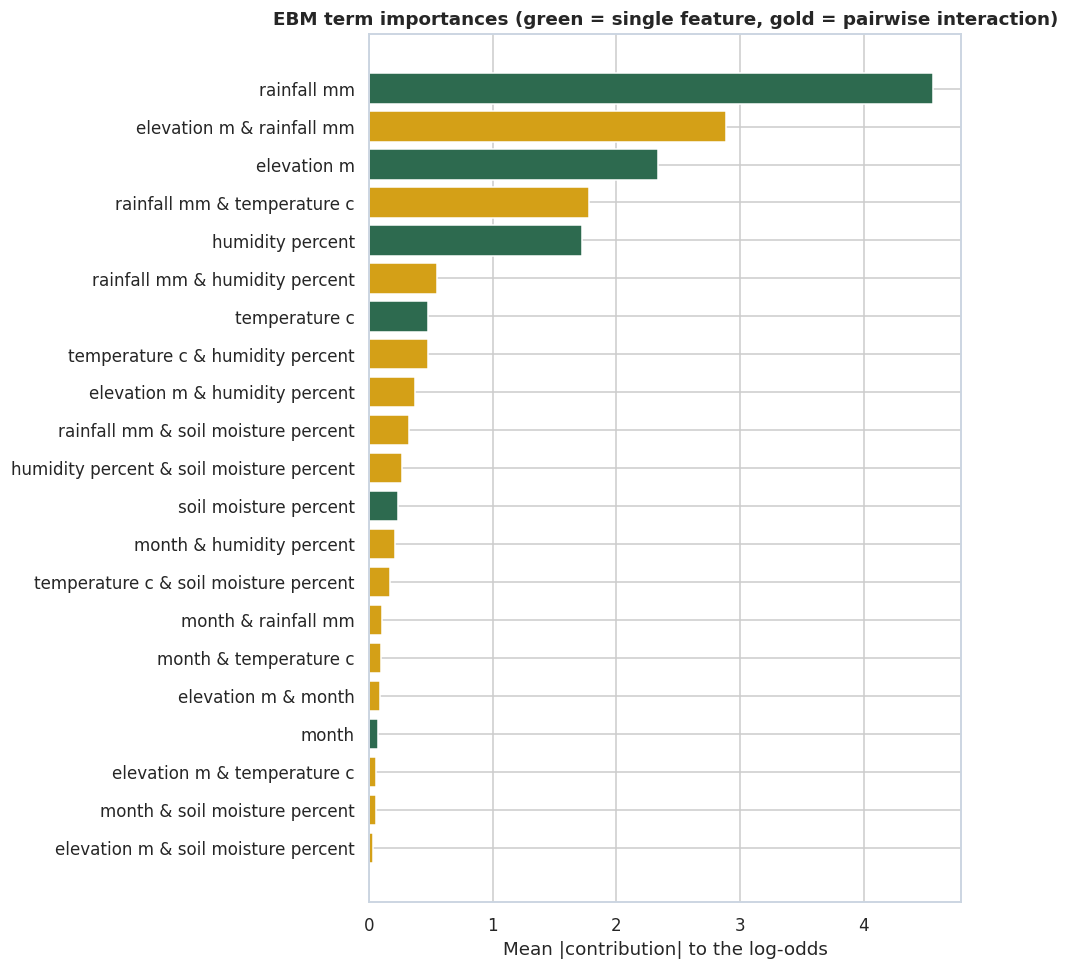

,0
rainfall_mm,4.564
elevation_m & rainfall_mm,2.889
elevation_m,2.337
rainfall_mm & temperature_c,1.776
humidity_percent,1.721
rainfall_mm & humidity_percent,0.548
temperature_c,0.478
temperature_c & humidity_percent,0.472
elevation_m & humidity_percent,0.370
rainfall_mm & soil_moisture_percent,0.318


In [35]:
ebm = final_model.named_steps["model"]
X_train_imp = final_model.named_steps["impute"].transform(X_train)   # what the EBM actually sees

importances = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values()
fig, ax = plt.subplots(figsize=(9, 0.38 * len(importances) + 1))
colors = [LEAF if " & " not in t else GOLD for t in importances.index]
ax.barh([t.replace("_", " ") for t in importances.index], importances.values, color=colors)
ax.set_xlabel("Mean |contribution| to the log-odds")
ax.set_title("EBM term importances (green = single feature, gold = pairwise interaction)")
plt.tight_layout(); savefig("ebm_term_importance"); plt.show()
importances.sort_values(ascending=False).round(3).head(10)

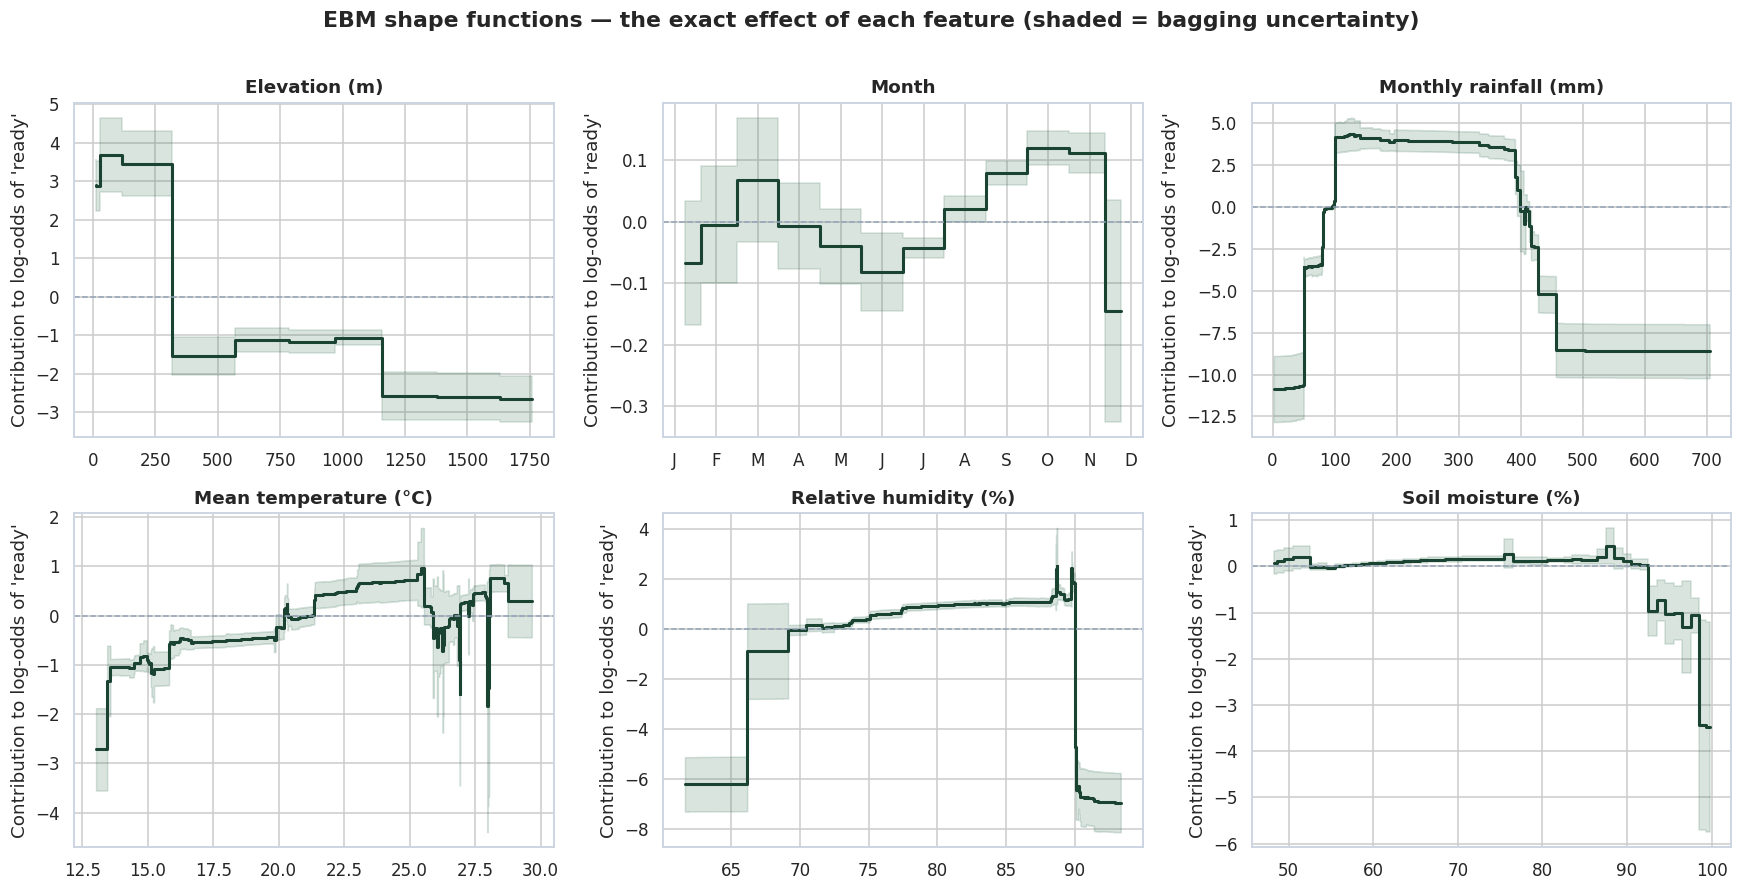

In [36]:
def ebm_shape(model, feature: str):
    """Return (x values, contribution, lower, upper) for a single-feature EBM term."""
    idx = model.term_names_.index(feature)
    data = model.explain_global().data(idx)
    names = np.asarray(data["names"], dtype=float)
    scores = np.asarray(data["scores"], dtype=float)
    x = (names[:-1] + names[1:]) / 2 if len(names) == len(scores) + 1 else names   # bin centres
    lower = np.asarray(data.get("lower_bounds", scores), dtype=float)
    upper = np.asarray(data.get("upper_bounds", scores), dtype=float)
    return x, scores, lower, upper

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feat in zip(axes.ravel(), MODEL_FEATURES):
    x, s, lo, hi = ebm_shape(ebm, feat)
    ax.fill_between(x, lo, hi, step="mid", color=LEAF, alpha=0.18)
    ax.step(x, s, where="mid", color=TEA_DARK, lw=2)
    ax.axhline(0, color="#94A3B8", lw=1, ls="--")
    ax.set_title(FEATURE_LABELS[feat]); ax.set_ylabel("Contribution to log-odds of 'ready'")
    if feat == "month":
        ax.set_xticks(range(1, 13), [m[0] for m in MONTH_NAMES])
plt.suptitle("EBM shape functions — the exact effect of each feature (shaded = bagging uncertainty)",
             fontweight="bold", y=1.01)
plt.tight_layout(); savefig("ebm_shape_functions"); plt.show()

In [37]:
for feat in ["rainfall_mm", "humidity_percent", "temperature_c", "soil_moisture_percent"]:
    x, s, _, _ = ebm_shape(ebm, feat)
    jumps = np.abs(np.diff(s))
    top = np.argsort(jumps)[::-1][:2]
    desc = ", ".join(f"≈{(x[i] + x[i + 1]) / 2:.1f} (Δ={s[i + 1] - s[i]:+.2f})" for i in sorted(top))
    print(f"{FEATURE_LABELS[feat]:28s} biggest jumps at {desc}")

Monthly rainfall (mm)        biggest jumps at ≈49.9 (Δ=+6.45), ≈100.1 (Δ=+3.80)
Relative humidity (%)        biggest jumps at ≈66.2 (Δ=+5.31), ≈90.0 (Δ=-3.60)
Mean temperature (°C)        biggest jumps at ≈26.9 (Δ=+1.84), ≈28.0 (Δ=-2.05)
Soil moisture (%)            biggest jumps at ≈92.5 (Δ=-1.01), ≈98.5 (Δ=-2.38)


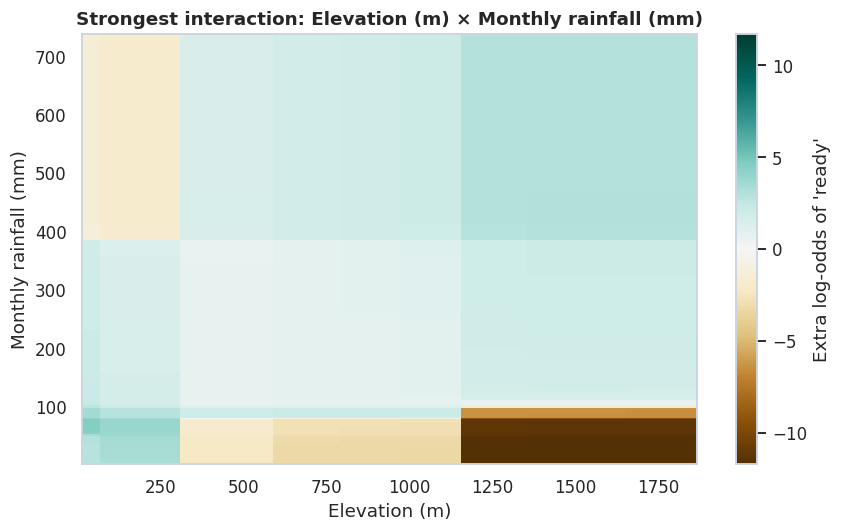

In [38]:
# The strongest pairwise interaction learned by EBM, drawn as a heat map
pair_terms = [t for t in ebm.term_names_ if " & " in t]
if pair_terms:
    top_pair = max(pair_terms, key=lambda t: ebm.term_importances()[ebm.term_names_.index(t)])
    d = ebm.explain_global().data(ebm.term_names_.index(top_pair))
    left, right = np.asarray(d["left_names"], float), np.asarray(d["right_names"], float)
    z = np.asarray(d["scores"], float)
    fig, ax = plt.subplots(figsize=(8, 5))
    mesh = ax.pcolormesh(left, right, z.T, cmap="BrBG", shading="flat",
                         vmin=-np.abs(z).max(), vmax=np.abs(z).max())
    fa, fb = top_pair.split(" & ")
    ax.set_xlabel(FEATURE_LABELS[fa]); ax.set_ylabel(FEATURE_LABELS[fb])
    ax.set_title(f"Strongest interaction: {FEATURE_LABELS[fa]} × {FEATURE_LABELS[fb]}")
    plt.colorbar(mesh, label="Extra log-odds of 'ready'")
    plt.tight_layout(); savefig("ebm_top_interaction"); plt.show()
else:
    print("The tuned EBM uses no interaction terms (interactions=0).")

**Reading the EBM curves (what the model has learned).** The plots show *exactly* how the model scores each input, and the printout above lists the sharpest learned thresholds:

* **Rainfall is by far the most important term, and it is a plateau.** Below ≈50 mm a month is pushed very strongly to "not ready"; between ≈50 and ≈100 mm the contribution climbs through zero; from ≈100 to ≈400 mm it is strongly positive; and from ≈400 mm it falls again, becoming strongly negative above ≈450 mm (water-logging, leaf damage and lost plucking days in storm months).
* **Elevation is next, together with its interaction with rainfall.** Estates below ≈300 m get a large positive contribution, mid-elevations a negative one and estates above ≈1,150 m a larger negative one — the model's way of encoding that cool up-country bushes grow slowly. The *elevation × rainfall* heat map shows that a dry month is forgiven in the low country but heavily penalised above ≈1,150 m.
* **Humidity rises gently up to a single sharp cliff at 90 %.** Above it (persistent mist and cloud at the monsoon peak) the contribution drops by about 8 log-odds. Very dry air (< ≈66 %) is also negative, but only a handful of months are that dry.
* **Temperature matters less than I expected once elevation is known** (the two are almost perfectly correlated). The curve rises steadily — cool months lower readiness, warm months raise it — and it is noisy between 26 and 28 °C where few rows sit; it also enters through the rainfall × temperature interaction (warm months need less rain).
* **Soil moisture** has a small effect, negative only for saturated soils (> ≈92 %). **Month** adds almost nothing (±0.1 log-odds) once the weather is known — the monsoon cycle acts *through* rainfall and humidity.

### 11.2 SHAP
SHAP distributes each prediction among the features using Shapley values from cooperative game theory. EBM is not a tree model, so I use the model-agnostic **exact** SHAP explainer (with only six features, all 2⁶ = 64 coalitions can be enumerated) on the predicted probability, with 100 training rows as the background distribution.

SHAP values for 300 test rows in 4s


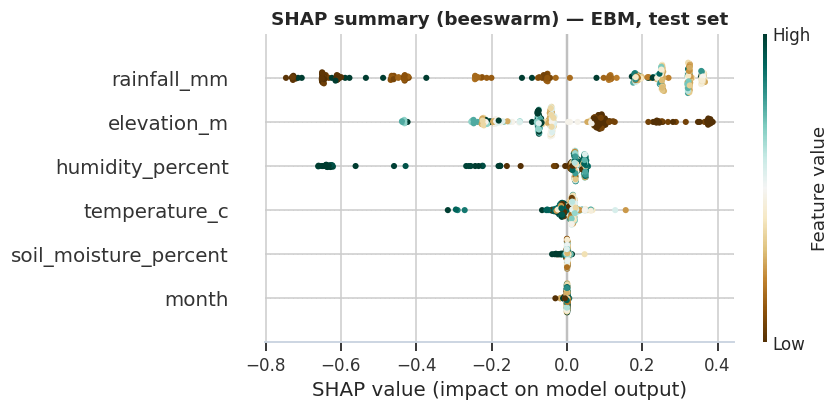

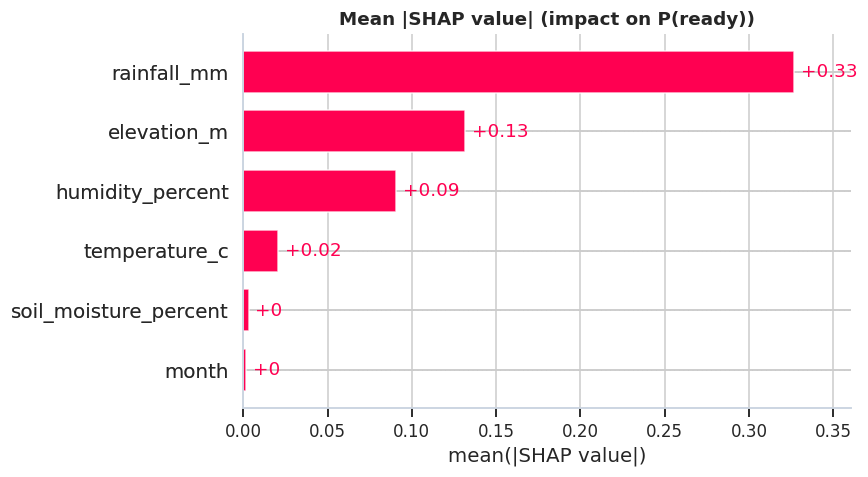

In [39]:
feature_cols = list(X_train.columns)

def predict_ready(X_array) -> np.ndarray:
    """Probability of 'ready' for an array/DataFrame — SHAP and LIME pass numpy arrays."""
    X_frame = pd.DataFrame(np.asarray(X_array, dtype=float), columns=feature_cols)
    return final_model.predict_proba(X_frame)[:, 1]

background = shap.sample(X_train, 100, random_state=SEED)
shap_explainer = shap.Explainer(predict_ready, shap.maskers.Independent(background), algorithm="exact",
                                feature_names=[FEATURE_LABELS[c] for c in feature_cols])
X_shap = X_test.sample(min(300, len(X_test)), random_state=SEED)
t0 = time.time()
shap_values = shap_explainer(X_shap)
print(f"SHAP values for {len(X_shap)} test rows in {time.time() - t0:.0f}s")

plt.figure()
shap.plots.beeswarm(shap_values, show=False, max_display=6, color=plt.get_cmap("BrBG"))
plt.title("SHAP summary (beeswarm) — EBM, test set"); plt.tight_layout(); savefig("shap_beeswarm"); plt.show()

plt.figure()
shap.plots.bar(shap_values, show=False, max_display=6)
plt.title("Mean |SHAP value| (impact on P(ready))"); plt.tight_layout(); savefig("shap_bar"); plt.show()

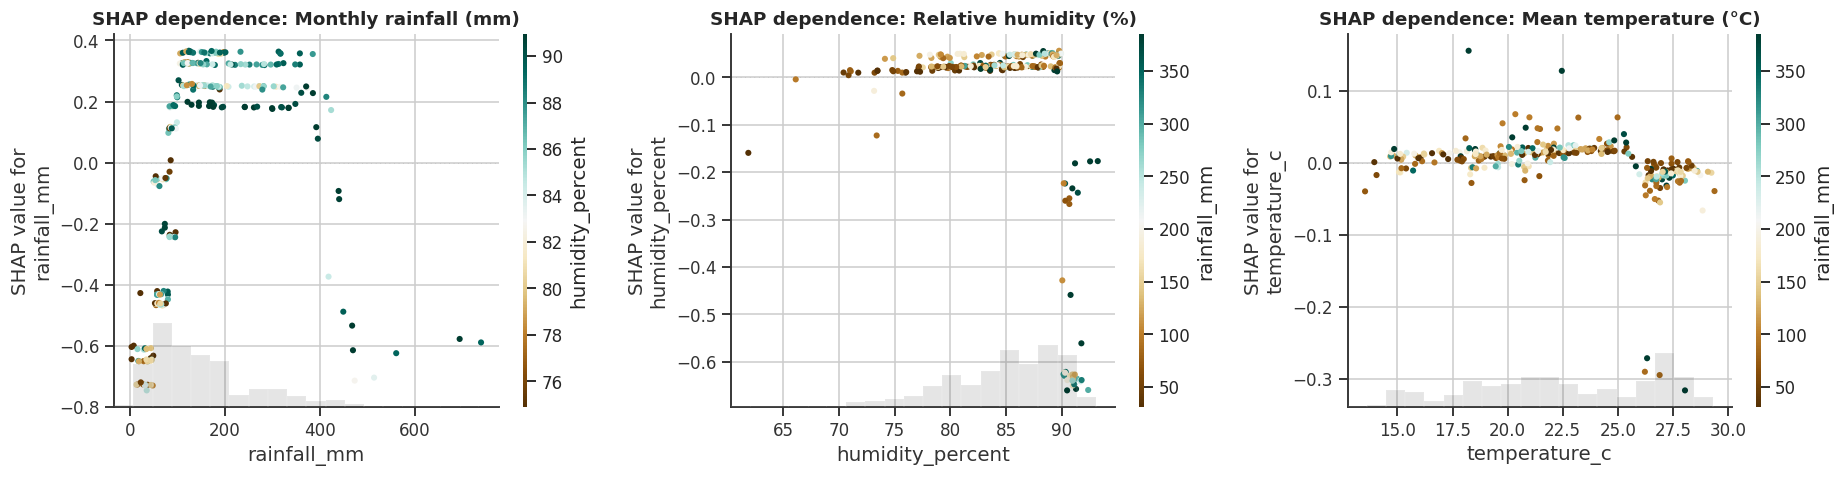

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
pairs = [("rainfall_mm", "humidity_percent"), ("humidity_percent", "rainfall_mm"),
         ("temperature_c", "rainfall_mm")]
for ax, (feat, colour_by) in zip(axes, pairs):
    # Explanation objects are indexed by column position
    i, j = feature_cols.index(feat), feature_cols.index(colour_by)
    shap.plots.scatter(shap_values[:, i], color=shap_values[:, j], ax=ax, show=False,
                       cmap=plt.get_cmap("BrBG"))
    ax.set_title(f"SHAP dependence: {FEATURE_LABELS[feat]}")
plt.tight_layout(); savefig("shap_dependence"); plt.show()

**SHAP interpretation.** The beeswarm ranks **rainfall** first, then **elevation**, **humidity**, temperature, soil moisture and month — the same ranking as EBM's own term importances, a good consistency check between an intrinsic and a post-hoc method. Low rainfall (brown dots) has large negative SHAP values, but so do the very highest rainfall values (dark green dots on the left): too little *and* too much rain hold the flush back. Low elevation (brown) pushes towards ready. The dependence plots show the SHAP value jumping around **50–80 mm** of rain, humidity above **90 %** turning sharply negative, and the colouring shows the interactions (e.g. the rainfall effect differs with humidity) — the same thresholds the rule-tree and EBM found.

In [41]:
xgb_model = tuned["XGBoost"].named_steps["model"]
tree_sv = shap.TreeExplainer(xgb_model)(final_model.named_steps["impute"].transform(X_shap))
rank = pd.DataFrame({
    "EBM (exact SHAP)": np.abs(shap_values.values).mean(0),
    "XGBoost (TreeSHAP)": np.abs(tree_sv.values).mean(0),
}, index=[FEATURE_LABELS[c] for c in feature_cols])
rank_norm = rank / rank.sum()
rho = stats.spearmanr(rank["EBM (exact SHAP)"], rank["XGBoost (TreeSHAP)"]).statistic
display(rank_norm.sort_values("EBM (exact SHAP)", ascending=False).round(3))
print(f"Spearman rank correlation of feature importance between EBM and XGBoost: {rho:.2f}")

,EBM (exact SHAP),XGBoost (TreeSHAP)
Monthly rainfall (mm),0.569,0.467
Elevation (m),0.229,0.202
Relative humidity (%),0.158,0.198
Mean temperature (°C),0.036,0.071
Soil moisture (%),0.005,0.033
Month,0.003,0.029


Spearman rank correlation of feature importance between EBM and XGBoost: 1.00


### 11.3 Local explanation of the held-out row: EBM vs SHAP vs LIME

Held-out row → P(ready) = 0.999, predicted = 1, actual = 1
EBM intercept (base log-odds) = 0.001


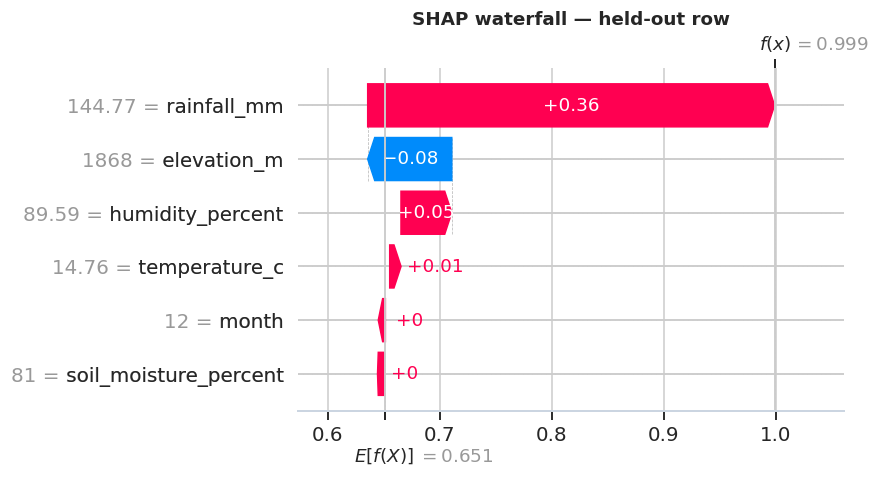

In [42]:
X_heldout = build_features(heldout_row)
p_heldout = final_model.predict_proba(X_heldout)[0, 1]
print(f"Held-out row → P(ready) = {p_heldout:.3f}, predicted = {int(p_heldout >= 0.5)}, "
      f"actual = {int(heldout_row[TARGET].iloc[0])}")

# (a) EBM's own exact local explanation (log-odds contributions)
local = ebm.explain_local(final_model.named_steps["impute"].transform(X_heldout), heldout_row[TARGET].values)
ld = local.data(0)
ebm_local = pd.Series(ld["scores"], index=ld["names"]).sort_values(key=np.abs, ascending=False)
print(f"EBM intercept (base log-odds) = {ebm.intercept_[0]:.3f}")

# (b) SHAP waterfall
sv_heldout = shap_explainer(X_heldout)
plt.figure()
shap.plots.waterfall(sv_heldout[0], show=False, max_display=7)
plt.title("SHAP waterfall — held-out row"); plt.tight_layout(); savefig("shap_waterfall_heldout"); plt.show()

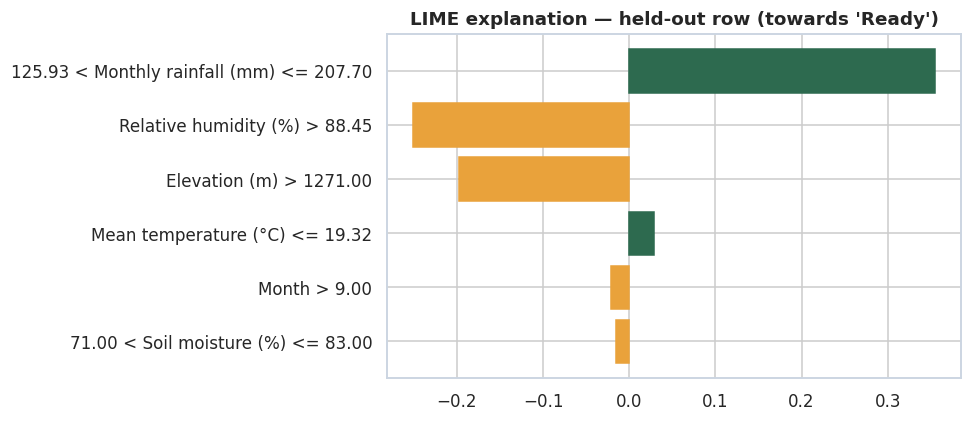

LIME local surrogate R² = 0.206
  125.93 < Monthly rainfall (mm) <= 207.70      +0.355
  Relative humidity (%) > 88.45                 -0.251
  Elevation (m) > 1271.00                       -0.197
  Mean temperature (°C) <= 19.32                +0.029
  Month > 9.00                                  -0.021
  71.00 < Soil moisture (%) <= 83.00            -0.015


In [43]:
lime_top = None
if LIME_AVAILABLE:
    lime_explainer = LimeTabularExplainer(
        training_data=X_train.values, feature_names=[FEATURE_LABELS[c] for c in feature_cols],
        class_names=["Not ready", "Ready"], mode="classification", discretize_continuous=True,
        random_state=SEED)
    lime_exp = lime_explainer.explain_instance(X_heldout.values[0], lambda a: np.column_stack(
        [1 - predict_ready(a), predict_ready(a)]), num_features=6, num_samples=4000)
    fig = lime_exp.as_pyplot_figure(label=1)
    fig.set_size_inches(9, 4)
    for bar in fig.axes[0].patches:   # recolour bars to my palette
        bar.set_color(LEAF if bar.get_width() > 0 else AMBER)
    plt.title("LIME explanation — held-out row (towards 'Ready')")
    plt.tight_layout(); savefig("lime_heldout"); plt.show()
    lime_top = lime_exp.as_list(label=1)
    print("LIME local surrogate R² =", round(lime_exp.score, 3))
    for rule, w in lime_top:
        print(f"  {rule:45s} {w:+.3f}")

In [44]:
# Side-by-side comparison of the three local explanations (top drivers, sign = direction)
shap_local = pd.Series(sv_heldout.values[0], index=[FEATURE_LABELS[c] for c in feature_cols])
comparison = pd.DataFrame({
    "EBM contribution (log-odds)": pd.Series({FEATURE_LABELS.get(k, k): v for k, v in ebm_local.items()
                                              if " & " not in k}),
    "SHAP value (probability)": shap_local,
})
if lime_top:
    lime_by_feature = {}
    for rule, w in lime_top:
        for c in feature_cols:
            if FEATURE_LABELS[c] in rule:
                lime_by_feature[FEATURE_LABELS[c]] = w
    comparison["LIME weight"] = pd.Series(lime_by_feature)
comparison = comparison.reindex(comparison["SHAP value (probability)"].abs().sort_values(ascending=False).index)
display(comparison.round(3))
top3 = {col: set(comparison[col].abs().sort_values(ascending=False).head(3).index) for col in comparison}
print("Top-3 drivers per method:", top3)

,EBM contribution (log-odds),SHAP value (probability),LIME weight
Monthly rainfall (mm),4.116,0.363,0.355
Elevation (m),-2.665,-0.075,-0.197
Relative humidity (%),1.177,0.045,-0.251
Mean temperature (°C),-0.840,0.010,0.029
Month,-0.145,0.004,-0.021
Soil moisture (%),0.143,0.001,-0.015


Top-3 drivers per method: {'EBM contribution (log-odds)': {'Relative humidity (%)', 'Elevation (m)', 'Monthly rainfall (mm)'}, 'SHAP value (probability)': {'Relative humidity (%)', 'Elevation (m)', 'Monthly rainfall (mm)'}, 'LIME weight': {'Relative humidity (%)', 'Elevation (m)', 'Monthly rainfall (mm)'}}


### 11.4 Partial dependence and ICE plots

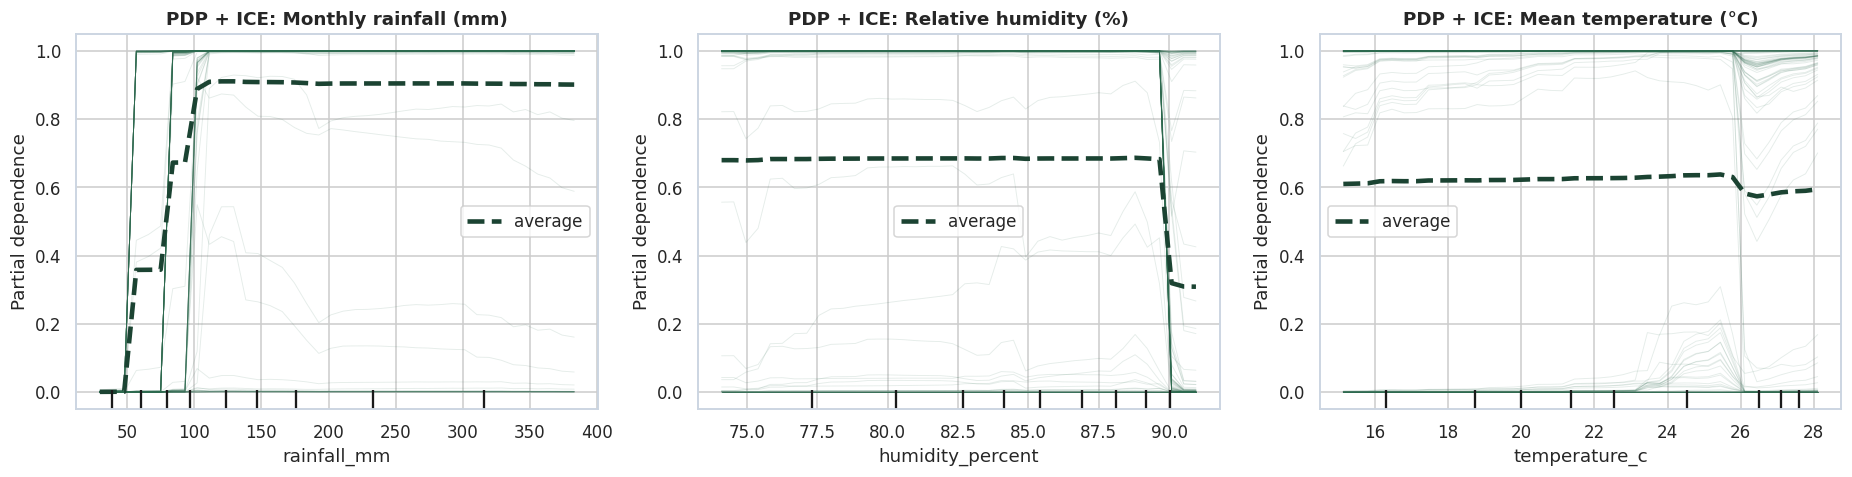

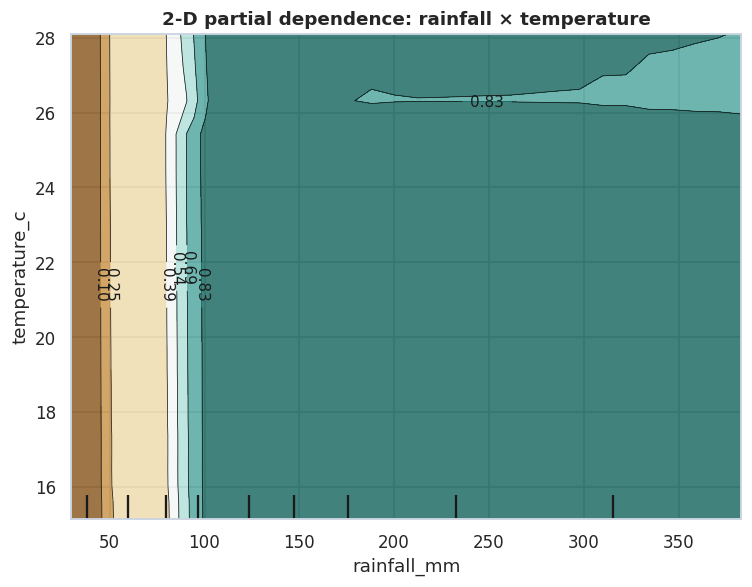

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, feat in zip(axes, ["rainfall_mm", "humidity_percent", "temperature_c"]):
    PartialDependenceDisplay.from_estimator(final_model, X_test, [feat], kind="both", subsample=120,
                                            grid_resolution=40, random_state=SEED, ax=ax,
                                            ice_lines_kw={"color": LEAF, "alpha": 0.12, "linewidth": 0.6},
                                            pd_line_kw={"color": TEA_DARK, "linewidth": 3})
    ax.set_title(f"PDP + ICE: {FEATURE_LABELS[feat]}")
plt.tight_layout(); savefig("pdp_ice"); plt.show()

fig, ax = plt.subplots(figsize=(7, 5.5))
PartialDependenceDisplay.from_estimator(final_model, X_test, [("rainfall_mm", "temperature_c")],
                                        grid_resolution=30, ax=ax, contour_kw={"cmap": "BrBG"})
ax.set_title("2-D partial dependence: rainfall × temperature")
plt.tight_layout(); savefig("pdp_2d_rain_temp"); plt.show()

**PDP/ICE interpretation.** The average curve (dashed line) shows P(ready) climbing in steps between ~50 and ~100 mm of rain and then staying flat, and collapsing from ≈0.68 to ≈0.3 when humidity passes 90 %. (scikit-learn draws PDPs over the 5th–95th percentile, so the storm-month drop above ~400 mm seen in the EBM curve lies outside this window.) The ICE lines (one per test month) are mostly flat at 0 or 1 and jump at *different* rainfall values — at ≈55 mm for some months and ≈100 mm for others — which is the elevation × rainfall interaction showing through. Temperature on its own barely moves the average, with a small dip near 26 °C. The 2-D plot shows the "sweet spot": **adequately wet** months are ready, **dry** months are not, and warm months need less rain.

### 11.5 Counterfactual: what would make a "not ready" month ready?
I implement a small, transparent version: for a "not ready" test month I search over realistic changes in the *weather* features (elevation and month cannot change) and report the smallest change that flips the prediction.

In [46]:
def simple_counterfactual(model, row: pd.DataFrame, changeable: dict, n_steps: int = 25):
    """Grid-search the smallest normalised change in `changeable` features that makes P(ready) >= 0.5."""
    base = row.iloc[0].copy()
    grids = {f: np.linspace(lo, hi, n_steps) for f, (lo, hi) in changeable.items()}
    best, best_cost = None, np.inf
    feats = list(changeable)
    # Search single-feature changes first, then pairs (enough for a 6-feature model).
    candidates = [(f,) for f in feats] + [(a, b) for i, a in enumerate(feats) for b in feats[i + 1:]]
    for combo in candidates:
        mesh = np.array(np.meshgrid(*[grids[f] for f in combo])).reshape(len(combo), -1).T
        trial = pd.DataFrame([base.values] * len(mesh), columns=row.columns)
        trial[list(combo)] = mesh
        proba = model.predict_proba(trial)[:, 1]
        ok = proba >= 0.5
        if not ok.any():
            continue
        span = np.array([changeable[f][1] - changeable[f][0] for f in combo])
        cost = (np.abs(mesh - base[list(combo)].values) / span).sum(1)
        cost[~ok] = np.inf
        i = int(np.argmin(cost))
        if cost[i] < best_cost:
            best_cost, best = cost[i], (combo, mesh[i], proba[i])
    return best

not_ready_rows = X_test[(final_model.predict(X_test) == 0)]
example = not_ready_rows.iloc[[0]]
cf = simple_counterfactual(final_model, example, {
    "rainfall_mm": (1, 600), "humidity_percent": (62, 93), "soil_moisture_percent": (47, 100)})
print("Original month:", example.round(1).to_dict("records")[0],
      f"→ P(ready)={final_model.predict_proba(example)[0, 1]:.3f}")
if cf:
    combo, values, p_new = cf
    changes = ", ".join(f"{FEATURE_LABELS[f]}: {example[f].iloc[0]:.1f} → {v:.1f}" for f, v in zip(combo, values))
    print(f"Smallest change that flips it to READY: {changes}  (new P(ready)={p_new:.3f})")
else:
    print("No realistic weather change flips this month — it is limited by elevation/season.")

Original month: {'elevation_m': 500.0, 'month': 1.0, 'rainfall_mm': 51.2, 'temperature_c': 21.9, 'humidity_percent': 88.2, 'soil_moisture_percent': 86.0} → P(ready)=0.001
Smallest change that flips it to READY: Monthly rainfall (mm): 51.1 → 100.8  (new P(ready)=1.000)


### 11.6 Does the model's behaviour agree with domain knowledge?
| Learned behaviour | Tea agronomy | Agrees? |
|---|---|---|
| Dry months (rain below ~50–80 mm) → not ready | Tea needs ~1,200–2,500 mm/year, well spread; drought stops shoot growth | ✅ |
| High elevation → less often ready | High-grown tea grows slowly in the cool climate (fewer flushes, prized flavour) | ✅ |
| Warm months flush on less rain (rain × temperature, elevation × rain) | Growth rate rises with temperature, so warm low-country bushes respond to smaller showers | ✅ |
| Very high humidity (> 90 %) → not ready | Persistent mist/cloud at the monsoon peak cuts sunshine and photosynthesis; blister-blight risk | ✅ |
| Extreme rainfall (> ~450 mm) and saturated soil (> ~92 %) → less ready | Water-logging stresses roots; storms damage shoots and stop plucking | ✅ |
| Cooler months → less ready, even at the same elevation | Shoot growth slows as temperature falls (dormancy in the cold up-country months) | ✅ |
| Low-grown regions ready most months; peaks in Apr and Oct–Nov | Inter-monsoon "flush" seasons in Sri Lanka | ✅ |

### 11.7 The management story
> *"Rain is the main switch. A month with less than about **50 mm** of rain will not be ready anywhere; above about **80 mm** most estates are ready — unless the month is a **misty, cloudy one with humidity above 90 %**, or a **storm month above about 450 mm** that water-logs the fields. Low-grown estates (Galle, Matara, Ratnapura, Kegalle) are warm enough to flush on smaller showers and are ready in most months, so they need permanent plucking rounds. High-grown estates (Nuwara Eliya, Dimbula, Haputale) need more rain and clearer skies, so expect slow months in January–February and July and plan extra labour for the April and October–November flushes."*

## 12. Saving the model and single-sample inference

I save the **whole pipeline** (imputer + EBM) with `joblib`, so the app and the API apply exactly the same preprocessing. I also write a small **model card** and the metrics the Streamlit app displays.

In [47]:
MODEL_PATH = MODEL_DIR / "tea_harvest_ebm.joblib"
joblib.dump(final_model, MODEL_PATH, compress=3)

# Metrics and curves for the app's comparison page
val_table.round(5).to_csv(MET_DIR / "model_comparison_validation.csv")
test_table.round(5).to_csv(MET_DIR / "model_comparison_test.csv")
cv_table.to_csv(MET_DIR / "cv_scores.csv")
search_table.assign(**{"best params": search_table["best params"].astype(str)}).to_csv(MET_DIR / "hyperparameter_search.csv")
roc_data = {}
for name in order:
    if name == "Majority baseline":
        continue
    fpr, tpr, _ = roc_curve(y_test, tuned[name].predict_proba(X_test)[:, 1])
    roc_data[name] = {"fpr": np.round(fpr, 4).tolist(), "tpr": np.round(tpr, 4).tolist()}
with open(MET_DIR / "roc_curves_test.json", "w") as f:
    json.dump(roc_data, f)

model_card = {
    "model": "Explainable Boosting Machine (interpret.glassbox.ExplainableBoostingClassifier)",
    "author": "Thejina",
    "task": "Binary classification of monthly tea harvest readiness (1 = ready)",
    "features": MODEL_FEATURES,
    "hyperparameters": {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                        for k, v in best_ebm_params.items() if k in
                        ["learning_rate", "max_bins", "interactions", "min_samples_leaf", "max_leaves",
                         "smoothing_rounds", "outer_bags", "random_state"]},
    "threshold": 0.5,
    "splits": split_summary.to_dict(),
    "test_metrics": {k: round(v, 4) for k, v in final_test.items()},
    "validation_checks": validation_checks,
    "library_versions": {"scikit-learn": sklearn.__version__, "interpret": interpret.__version__,
                         "python": sys.version.split()[0]},
    "trained_on_rows": int(len(X_train)),
    "intended_use": "Decision support for estate managers / TRI advisers; not a substitute for field inspection.",
}
with open(MODEL_DIR / "model_card.json", "w") as f:
    json.dump(model_card, f, indent=2, default=str)
heldout_row.to_json(MET_DIR / "heldout_sample.json", orient="records", indent=2)
print(f"Saved {MODEL_PATH.name} ({MODEL_PATH.stat().st_size / 1024:.0f} KB), model_card.json and metrics.")

Saved tea_harvest_ebm.joblib (1947 KB), model_card.json and metrics.


In [48]:
# Single-sample inference exactly as the app/API will do it: load from disk, predict the unseen row.
try:
    loaded = joblib.load(MODEL_PATH)
except Exception as err:
    raise RuntimeError(f"Could not load the saved model: {err}")

sample = heldout_row.drop(columns=[TARGET])
proba = loaded.predict_proba(build_features(sample))[0, 1]
print("Input:", sample[["region", "year", "month", "rainfall_mm", "temperature_c",
                         "humidity_percent", "soil_moisture_percent"]].to_dict("records")[0])
print(f"Prediction: {'READY ✅' if proba >= 0.5 else 'NOT READY ⏳'}   P(ready) = {proba:.3f}   "
      f"(true label = {int(heldout_row[TARGET].iloc[0])})")
assert np.isclose(proba, p_heldout), "Loaded model must give the same answer as the in-memory model"

Input: {'region': 'Nuwara Eliya', 'year': 2024, 'month': 12, 'rainfall_mm': 144.77, 'temperature_c': 14.76, 'humidity_percent': 89.59, 'soil_moisture_percent': 81.0}
Prediction: READY ✅   P(ready) = 0.999   (true label = 1)


## 13. Extension: forecasting next month's readiness

Because the current-month label follows the current-month weather almost deterministically, I also frame the **harder and more useful** planning question: *using only what is known at the end of this month, will the region be ready **next** month?* Estate managers schedule labour weeks ahead, so this is closer to a real decision.

Features (all known at the end of month *t*): this month's weather, last month's rainfall, the 3-month rainfall total, this month's readiness, elevation, and the target month. I use a strict **time split** (train 2001–2019, test 2020–2024) and lag features computed per region, so nothing from the future leaks in.

In [49]:
def next_month_frame(data: pd.DataFrame) -> pd.DataFrame:
    """Per region, sorted by time: features at month t, target = readiness at month t+1."""
    d = data.sort_values(["region", "year", "month"]).copy()
    g = d.groupby("region")
    d["rain_lag1"] = g["rainfall_mm"].shift(1)
    d["rain_3m"] = g["rainfall_mm"].transform(lambda s: s.rolling(3, min_periods=3).sum())
    d["ready_now"] = d[TARGET]
    d["target_next"] = g[TARGET].shift(-1)
    d["next_month"] = d["month"] % 12 + 1
    return d.dropna(subset=["rain_lag1", "rain_3m", "target_next"])

nm = next_month_frame(df)
nm_features = ["elevation_m", "next_month", "rainfall_mm", "temperature_c", "humidity_percent",
               "soil_moisture_percent", "rain_lag1", "rain_3m", "ready_now"]
tr_m, te_m = nm.year <= 2019, nm.year >= 2020
Xn_tr, yn_tr = nm.loc[tr_m, nm_features], nm.loc[tr_m, "target_next"].astype(int)
Xn_te, yn_te = nm.loc[te_m, nm_features], nm.loc[te_m, "target_next"].astype(int)

def nm_cyclic(X):
    X = X.copy()
    X["m_sin"], X["m_cos"] = np.sin(2 * np.pi * X.next_month / 12), np.cos(2 * np.pi * X.next_month / 12)
    return X.drop(columns="next_month")

next_models = {
    "Persistence (ready next = ready now)": None,
    "Logistic Regression": Pipeline([("impute", imputer()), ("cyc", FunctionTransformer(nm_cyclic)),
                                     ("scale", StandardScaler()),
                                     ("model", LogisticRegression(C=0.3, max_iter=3000))]),
    "XGBoost": tree_pipeline(XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                           colsample_bytree=0.8, min_child_weight=5, reg_lambda=5,
                                           eval_metric="logloss", random_state=SEED, n_jobs=N_JOBS)),
    "EBM (new)": tree_pipeline(ExplainableBoostingClassifier(learning_rate=0.01, interactions=5, outer_bags=4,
                                                             min_samples_leaf=8, max_bins=128,
                                                             random_state=SEED, n_jobs=N_JOBS)),
}
nm_rows = []
for name, m in next_models.items():
    if m is None:   # naive baseline: assume next month looks like this month
        pred = Xn_te["ready_now"].values
        nm_rows.append({"model": name, "Accuracy": accuracy_score(yn_te, pred), "F1": f1_score(yn_te, pred),
                        "ROC-AUC": roc_auc_score(yn_te, pred), "Balanced acc.": balanced_accuracy_score(yn_te, pred)})
        continue
    m.fit(Xn_tr, yn_tr)
    met = evaluate(m, Xn_te, yn_te)
    nm_rows.append({"model": name, **{k: met[k] for k in ["Accuracy", "F1", "ROC-AUC", "Balanced acc."]}})
next_month_table = pd.DataFrame(nm_rows).set_index("model").round(4)
next_month_table.to_csv(MET_DIR / "next_month_forecast.csv")
next_month_table

,Accuracy,F1,ROC-AUC,Balanced acc.
model,,,,
Persistence (ready next = ready now),0.7242,0.7911,0.6937,0.6937
Logistic Regression,0.7288,0.7995,0.7811,0.6870
XGBoost,0.7149,0.7768,0.7560,0.6992
EBM (new),0.6703,0.7452,0.7041,0.6429


## 14. Fairness across zones, critical discussion and ethics

### 14.1 Is performance equal across elevation zones?
"Bias" here is not about people but about **regions**: a model that works well for low-country estates and badly for up-country estates would unfairly disadvantage some growers.

In [50]:
test_frame = df_model.loc[X_test.index]
zone_rows = []
for zone in zone_order:
    idx = test_frame.zone == zone
    met = evaluate(final_model, X_test[idx], y_test[idx])
    zone_rows.append({"zone": zone, "test rows": int(idx.sum()), "ready rate": y_test[idx].mean(),
                      "Accuracy": met["Accuracy"], "F1": met["F1"],
                      "Recall (ready)": met["Recall (ready)"], "Recall (not ready)": met["Recall (not ready)"]})
fairness = pd.DataFrame(zone_rows).set_index("zone").round(4)
fairness.to_csv(MET_DIR / "fairness_by_zone.csv")
fairness

,test rows,ready rate,Accuracy,F1,Recall (ready),Recall (not ready)
zone,,,,,,
low-grown,176,0.8295,1.0000,1.0000,1.0000,1.0000
mid-grown,177,0.5254,0.9774,0.9783,0.9677,0.9881
high-grown,123,0.4390,1.0000,1.0000,1.0000,1.0000


### 14.2 Limitations of the model
* **Rule-like label.** Section 10 showed that `harvest_ready` follows weather thresholds. The model reproduces those rules almost perfectly, but its 99 % does **not** mean it predicts real plucking outcomes that well; the next-month task (Section 13) is the realistic benchmark.
* **Monthly resolution.** Flushes develop over 7–10 days; monthly totals hide dry spells and storms within a month.
* **No yield or quality target.** The model says *ready / not ready*, not *how much* green leaf or what grade.
* **Threshold 0.5** is a neutral default; an estate that values missed flushes more than wasted rounds should move it (the app shows the probability for that reason).

### 14.3 Data-quality issues
* **Gridded weather:** several regions share identical rainfall series, so local micro-climates (e.g. Haputale vs Ella) are not distinguished.
* **NDVI is a lookup table**, not satellite data; `temperature_c` is a lapse-rate correction of a grid value.
* **Unclear provenance of the label.** The file does not document who assigned `harvest_ready` or how; I treat it as an expert/rule-based label and say so openly.
* **Perfectly clean panel** (no missing values at all) is itself a warning sign that the file has been processed or partly simulated.

### 14.4 Risks of bias or unfairness
* **Regional bias:** smallholders (who produce most of Sri Lanka's low-grown tea) and estates in regions not in the dataset (e.g. Kurunegala, Hantane micro-zones) are not represented. Leave-one-region-out results are encouraging, but a new region far outside 11–1,868 m would be extrapolation — my app warns about this.
* **Zone performance** is similar across zones (table above), so the model does not systematically favour low-country estates.
* **Automation bias:** managers might trust a green "READY" badge over their own field inspection. The app therefore always shows the probability and the reasons.

### 14.5 Real-world impact and ethical considerations
* **Positive impact:** better scheduling of pluckers (Sri Lanka's estate sector faces chronic labour shortages), fewer wasted rounds, fewer missed flushes, better leaf quality, and planning for factory capacity.
* **Workers' livelihoods:** plucker income is often linked to days worked and kilograms plucked. A tool that *reduces* scheduled days could cut incomes; it should be used to *re-allocate* labour across fields, not to cut workers' days.
* **Transparency:** using a glass-box model means the logic can be audited by TRI scientists, managers and worker representatives.
* **Data ethics:** the data contains no personal information. If extended with estate-level yields or worker data, consent and anonymisation would be required.
* **Climate change:** the 2001–2024 relationships may shift; my MLOps setup monitors input drift and retrains when needed.

## 15. Conclusion

* I framed a Sri Lankan plantation problem — **is a tea region harvest-ready this month?** — as binary classification on 3,168 region-months from 11 regions (2001–2024).
* EDA revealed strong elevation and monsoon effects, weak linear correlations and heavy redundancy (region/elevation/zone, NDVI, two temperatures), so I modelled six non-redundant features inside leakage-safe pipelines.
* I applied a **new algorithm, the Explainable Boosting Machine**, and compared it with a majority floor, logistic regression, a decision tree, Random Forest, XGBoost, LightGBM, CatBoost and stacking, all with designed hyperparameter searches.
* EBM matched the best black-box ensembles (≈99 % accuracy/F1 and ROC-AUC ≈ 0.999 on the untouched test set; no significant difference by McNemar) while being fully interpretable.
* Five validation checks (time split, leave-one-region-out, learning curve, permutation test, rule recovery) showed the score is genuine for this label — and revealed that the label is rule-based, which I discuss openly; the harder next-month forecast gives the realistic planning benchmark.
* EBM shape functions, SHAP, LIME, PDP/ICE and counterfactuals all tell the same, agronomically sensible story: **rain above ~80 mm (≈50 mm in the warm low country) makes a month ready; dry months, misty months above 90 % humidity and storm months above ~450 mm hold the flush back, and high-grown estates are ready less often.**
* The saved pipeline powers my Streamlit app and a FastAPI service deployed with my MLOps pipeline (GitHub + DVC + DagsHub/MLflow + Docker + GitHub Actions + Azure Container Apps).